# EDA and cleaning of the new Miami datasets

This notebook validates ZIP coverage and profiles home values, rental values, transit,
and Miami rents. Section 5 uses the transit EDA format. Sections 6–9 inspect observed
rent values; sections 10–14 prepare model fields, audit zeros, drop the requested
columns, and save `Miami-rents-cleaned.csv` with median imputation. Outlier treatment
is pending; the original `miami-rents.csv` is not overwritten.


In [55]:
from pathlib import Path
import math
import sys
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').is_dir(): PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / 'data'
NOTEBOOKS_DIR = PROJECT_ROOT / 'notebooks'
# Force a fresh import from this repository's notebooks folder. Jupyter otherwise
# may reuse an older cached version of clean_miami_rents.py.
notebooks_path = str(NOTEBOOKS_DIR)
sys.path = [path for path in sys.path if path != notebooks_path]
sys.path.insert(0, notebooks_path)
import importlib
importlib.invalidate_caches()
sys.modules.pop('clean_miami_rents', None)
rent_cleaning = importlib.import_module('clean_miami_rents')
clean_miami_rents = rent_cleaning.clean_miami_rents
MODEL_FEATURE_COLUMNS = rent_cleaning.MODEL_FEATURE_COLUMNS
METADATA_COLUMNS = rent_cleaning.METADATA_COLUMNS
EXPLANATION_COLUMNS = rent_cleaning.EXPLANATION_COLUMNS
prepare_rent_table = rent_cleaning.prepare_rent_table
fit_rent_imputer = rent_cleaning.fit_rent_imputer
impute_rent_table = rent_cleaning.impute_rent_table
DROP_COLUMNS = rent_cleaning.DROP_COLUMNS
EXCLUDED_MONTH_COLUMNS = rent_cleaning.EXCLUDED_MONTH_COLUMNS
MEDIAN_IMPUTE_COLUMNS = rent_cleaning.MEDIAN_IMPUTE_COLUMNS
fill_missing_rent_direction = rent_cleaning.fill_missing_rent_direction
NEW_DATA_DIR = DATA_DIR / 'cleaned' / 'new'
RAW_DATA_DIR = DATA_DIR / 'raw' 
ZCTA_PATH = DATA_DIR / 'raw' / 'miami_dade_zctas.txt'
DATASETS = {
    'Miami Home Values': {'path': RAW_DATA_DIR / 'new' / 'Miami_home_values.csv', 'zip_column': 'RegionName'},
    'Miami Rental Values': {'path': RAW_DATA_DIR / 'new' / 'Miami_rental_values.csv', 'zip_column': 'RegionName'},
    'Miami Transit': {'path': RAW_DATA_DIR / 'new' / 'miami_transit.csv', 'zip_column': 'zip_code'},
    'Miami Rents': {'path': RAW_DATA_DIR / 'miami-rents.csv', 'zip_column': 'zip_code'},
}
def normalize_zip_codes(values):
    return values.astype('string').str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(5)
allowed_zips = {line.strip().zfill(5) for line in ZCTA_PATH.read_text(encoding='utf-8').splitlines() if line.strip()}
if not allowed_zips: raise ValueError(f'Empty Miami-Dade ZIP allowlist: {ZCTA_PATH}')
cleaned_data, validation_rows = {}, []
for dataset_name, config in DATASETS.items():
    path, zip_column = config['path'], config['zip_column']
    frame = pd.read_csv(path, dtype={zip_column: 'string'})
    if dataset_name == 'Miami Rents':
        frame = clean_miami_rents(frame)
    if zip_column not in frame.columns: raise ValueError(f'{path.name} is missing {zip_column}')
    frame[zip_column] = normalize_zip_codes(frame[zip_column])
    in_scope = frame[zip_column].isin(allowed_zips)
    cleaned_data[dataset_name] = frame.loc[in_scope].copy()
    validation_rows.append({'dataset': dataset_name, 'original_rows': len(frame), 'rows_dropped_outside_miami_dade': int((~in_scope).sum()), 'rows_remaining': int(in_scope.sum()), 'original_columns': len(frame.columns), 'columns_dropped': 0, 'remaining_columns': len(frame.columns), 'out_of_scope_zips': sorted(frame.loc[~in_scope, zip_column].dropna().unique())})
validation_summary = pd.DataFrame(validation_rows)
display(validation_summary.drop(columns='out_of_scope_zips'))
display(validation_summary[['dataset', 'out_of_scope_zips']])

,dataset,original_rows,rows_dropped_outside_miami_dade,rows_remaining,original_columns,columns_dropped,remaining_columns
0,Miami Home Values,30,0,30,17,0,17
1,Miami Rental Values,29,0,29,17,0,17
2,Miami Transit,78,0,78,21,0,21
3,Miami Rents,84,0,84,25,0,25


,dataset,out_of_scope_zips
0,Miami Home Values,[]
1,Miami Rental Values,[]
2,Miami Transit,[]
3,Miami Rents,[]


## 1. Shapes, schemas, missing values, and duplicates

This section records the baseline schema and audits missing values, duplicate rows, and duplicate ZIP keys. Missing Zillow observations remain missing because they represent unavailable estimates, not zero-dollar values.

In [56]:
schema_rows, missing_rows, duplicate_rows = [], [], []
for dataset_name, config in DATASETS.items():
    frame, zip_column = cleaned_data[dataset_name], config['zip_column']
    schema_rows.append({'dataset': dataset_name, 'rows': len(frame), 'columns': len(frame.columns), 'column_names': ', '.join(frame.columns)})
    duplicate_rows.append({'dataset': dataset_name, 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_zip_codes': int(frame[zip_column].duplicated().sum())})
    for column in frame.columns: missing_rows.append({'dataset': dataset_name, 'column': column, 'missing_count': int(frame[column].isna().sum()), 'missing_percent': round(frame[column].isna().mean() * 100, 2)})
display(pd.DataFrame(schema_rows))
missing_profile = pd.DataFrame(missing_rows)
display(missing_profile.query('missing_count > 0').sort_values(['dataset', 'missing_count'], ascending=[True, False]))
display(pd.DataFrame(duplicate_rows))
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} dtypes')
    display(frame.dtypes.rename('dtype').to_frame())

,dataset,rows,columns,column_names
0,Miami Home Values,30,17,"RegionID, SizeRank, RegionName, RegionType, St..."
1,Miami Rental Values,29,17,"RegionID, SizeRank, RegionName, RegionType, St..."
2,Miami Transit,78,21,"zip_code, transit_stop_count, unique_route_cou..."
3,Miami Rents,84,25,"zip_code, zori_2026_01, zori_2026_02, zori_202..."


,dataset,column,missing_count,missing_percent
56,Miami Rents,zori_2026_01,56,66.67
57,Miami Rents,zori_2026_02,56,66.67
58,Miami Rents,zori_2026_03,55,65.48
59,Miami Rents,zori_2026_04,55,65.48
60,Miami Rents,zori_2026_05,55,65.48
61,Miami Rents,zori_2026_06,55,65.48
62,Miami Rents,zori_2026_07,55,65.48
74,Miami Rents,rent_24_month_change_pct,18,21.43
73,Miami Rents,rent_12_month_change_pct,14,16.67
75,Miami Rents,rent_volatility,14,16.67


,dataset,duplicate_rows,duplicate_zip_codes
0,Miami Home Values,0,0
1,Miami Rental Values,0,0
2,Miami Transit,0,0
3,Miami Rents,0,0



Miami Home Values dtypes


,dtype
RegionID,int64
SizeRank,int64
RegionName,string[python]
RegionType,object
StateName,object
State,object
City,object
Metro,object
CountyName,object
2026-01-31,float64



Miami Rental Values dtypes


,dtype
RegionID,int64
SizeRank,int64
RegionName,string[python]
RegionType,object
StateName,object
State,object
City,object
Metro,object
CountyName,object
2026-01-31,float64



Miami Transit dtypes


,dtype
zip_code,string[python]
transit_stop_count,int64
unique_route_count,int64
transit_types,object
bus_route_count,int64
metrorail_route_count,int64
metromover_route_count,int64
weekday_departures,int64
saturday_departures,float64
sunday_departures,float64



Miami Rents dtypes


,dtype
zip_code,string[python]
zori_2026_01,float64
zori_2026_02,float64
zori_2026_03,float64
zori_2026_04,float64
zori_2026_05,float64
zori_2026_06,float64
zori_2026_07,float64
zori_2026_08,float64
zori_latest_rent,float64


## 2. Numeric profiling and distribution plots

The profile reports descriptive statistics, zero counts, unique values, skewness, and negative values. ZIP identifiers and date columns are excluded from plots.


Miami Home Values numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
RegionID,30.0,0,0,30,72454.866667,23.279017,72426.000000,7.249400e+04,0.342094,0
SizeRank,30.0,0,0,30,4576.566667,3930.984773,532.000000,2.035600e+04,2.329280,0
2026-01-31,30.0,0,0,30,637456.064366,246781.278136,303104.816100,1.522705e+06,2.125660,0
2026-02-28,30.0,0,0,30,638200.375639,247215.932502,301956.361929,1.511917e+06,2.088572,0
2026-03-31,30.0,0,0,30,638571.596977,247255.910840,300867.061280,1.496397e+06,2.046965,0
2026-04-30,30.0,0,0,30,638036.660842,247327.769418,299412.301999,1.483427e+06,2.018276,0
2026-05-31,30.0,0,0,30,637781.322693,247688.854525,298487.466130,1.478049e+06,2.005351,0
2026-06-30,30.0,0,0,30,638844.290351,249661.377210,297789.177069,1.483411e+06,2.010223,0
2026-07-31,30.0,0,0,30,641542.905339,252529.400865,297981.490916,1.493698e+06,2.018991,0
2026-08-31,30.0,0,0,30,645014.663860,256016.623516,298325.005237,1.503923e+06,2.021920,0


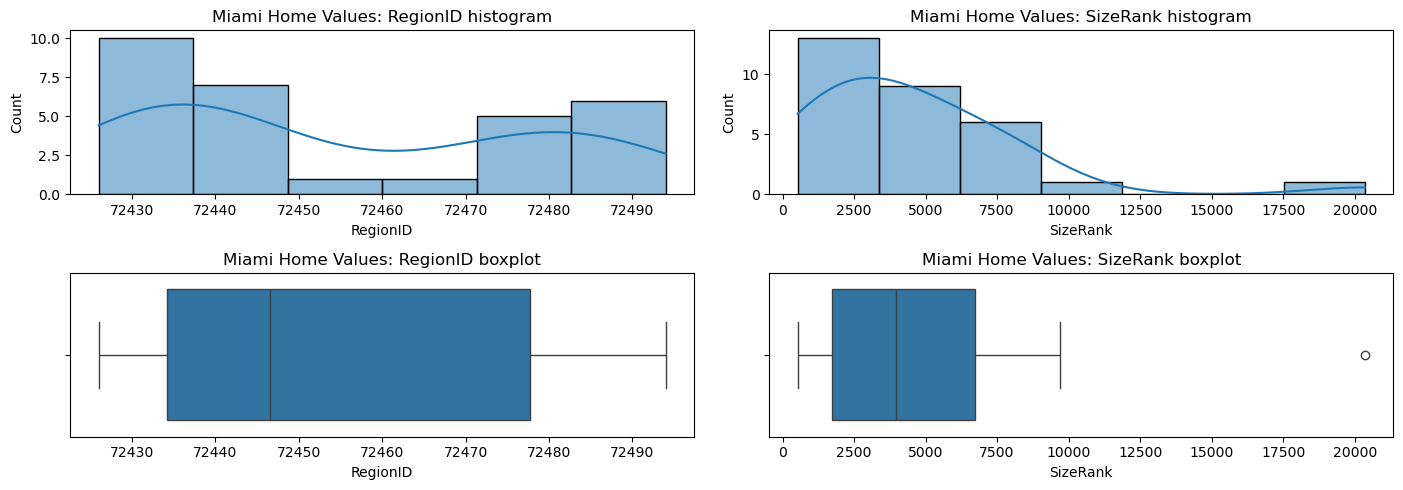


Miami Rental Values numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
RegionID,29.0,0,0,29,72453.689655,22.764483,72426.000000,72494.000000,0.417262,0
SizeRank,29.0,0,0,29,4495.034483,3974.666540,532.000000,20356.000000,2.397594,0
2026-01-31,29.0,0,1,29,2711.552407,705.787464,0.000000,3856.182758,-1.813939,0
2026-02-28,29.0,0,1,29,2718.248026,707.092390,0.000000,3866.957877,-1.812635,0
2026-03-31,29.0,0,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
2026-04-30,29.0,0,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
2026-05-31,29.0,0,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
2026-06-30,29.0,0,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
2026-07-31,29.0,0,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
2026-08-31,29.0,0,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0


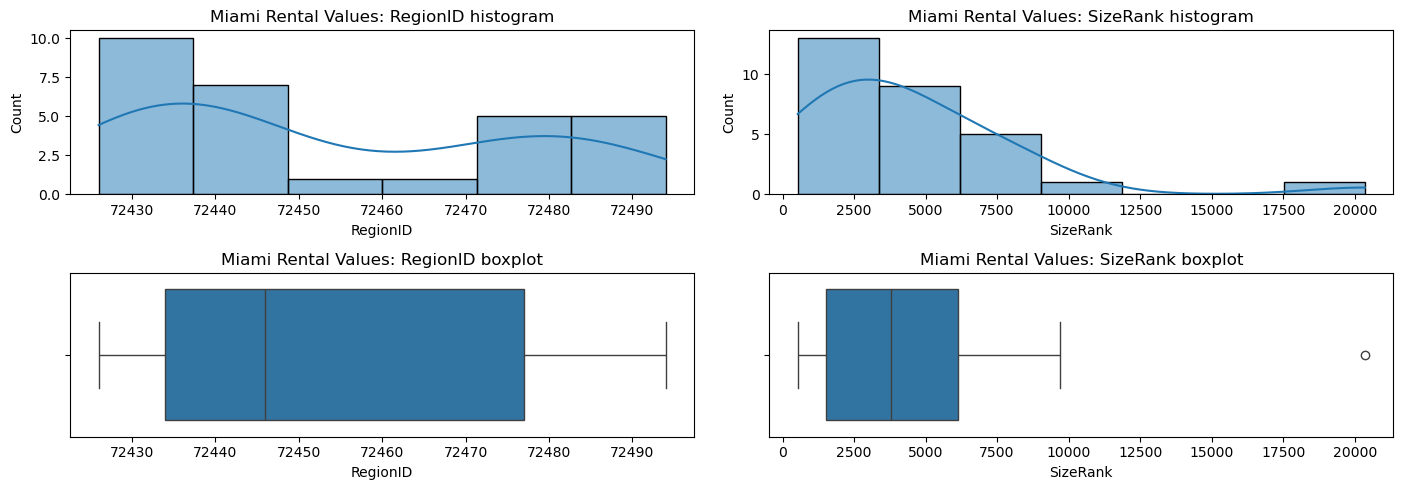


Miami Transit numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
transit_stop_count,78.0,0,0,66,8.905128e+01,54.129690,1.000000e+00,2.510000e+02,0.436088,0
unique_route_count,78.0,0,0,20,8.820513e+00,5.445703,1.000000e+00,2.800000e+01,1.058572,0
bus_route_count,78.0,0,0,21,8.538462e+00,5.031569,1.000000e+00,2.600000e+01,0.894721,0
metrorail_route_count,78.0,0,64,2,1.794872e-01,0.386244,0.000000e+00,1.000000e+00,1.703315,0
metromover_route_count,78.0,0,73,3,1.025641e-01,0.413718,0.000000e+00,2.000000e+00,4.114727,0
weekday_departures,78.0,0,0,78,5.165205e+03,3685.067299,1.500000e+01,1.880200e+04,0.917631,0
saturday_departures,75.0,3,0,75,4.345240e+03,3261.318026,1.500000e+01,1.710000e+04,1.154959,0
sunday_departures,75.0,3,0,74,3.196293e+03,2425.817175,1.400000e+01,1.283700e+04,1.288387,0
weekday_median_headway_minutes,78.0,0,0,46,3.055988e+01,10.724580,9.000000e+00,6.000000e+01,0.713755,0
weekend_median_headway_minutes,75.0,3,0,68,2.494300e+01,18.131652,7.183333e+00,9.723333e+01,2.732612,0


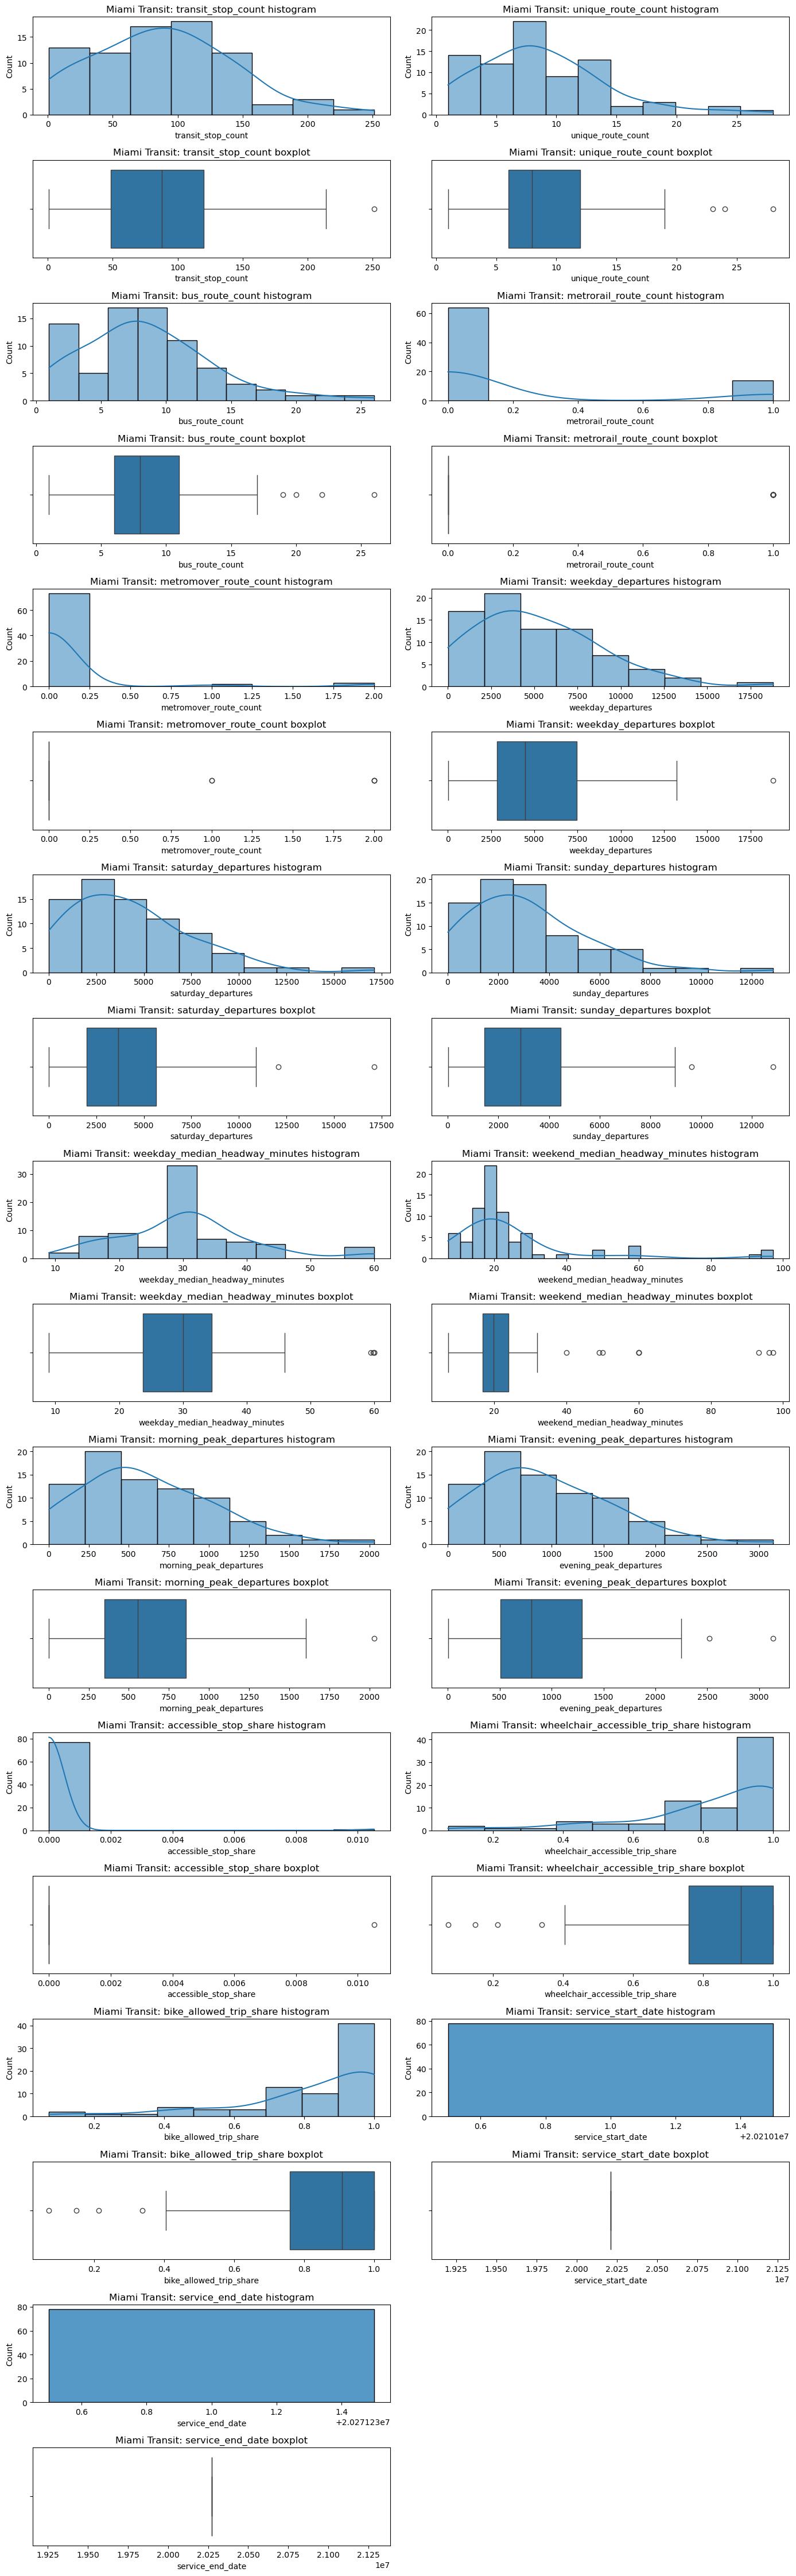


Miami Rents numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
zori_2026_01,28.0,56,0,28,2808.393565,484.297892,2122.036267,3856.182758,0.507841,0
zori_2026_02,28.0,56,0,28,2815.328313,484.831759,2137.609440,3866.957877,0.526775,0
zori_2026_03,29.0,55,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
zori_2026_04,29.0,55,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
zori_2026_05,29.0,55,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
zori_2026_06,29.0,55,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
zori_2026_07,29.0,55,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
zori_2026_08,74.0,10,0,74,2817.263804,722.147531,2062.500000,7161.927609,3.414464,0
zori_latest_rent,74.0,10,0,74,2817.263804,722.147531,2062.500000,7161.927609,3.414464,0
hud_efficiency,84.0,0,0,61,2102.500000,387.891660,1530.000000,2930.000000,0.713876,0


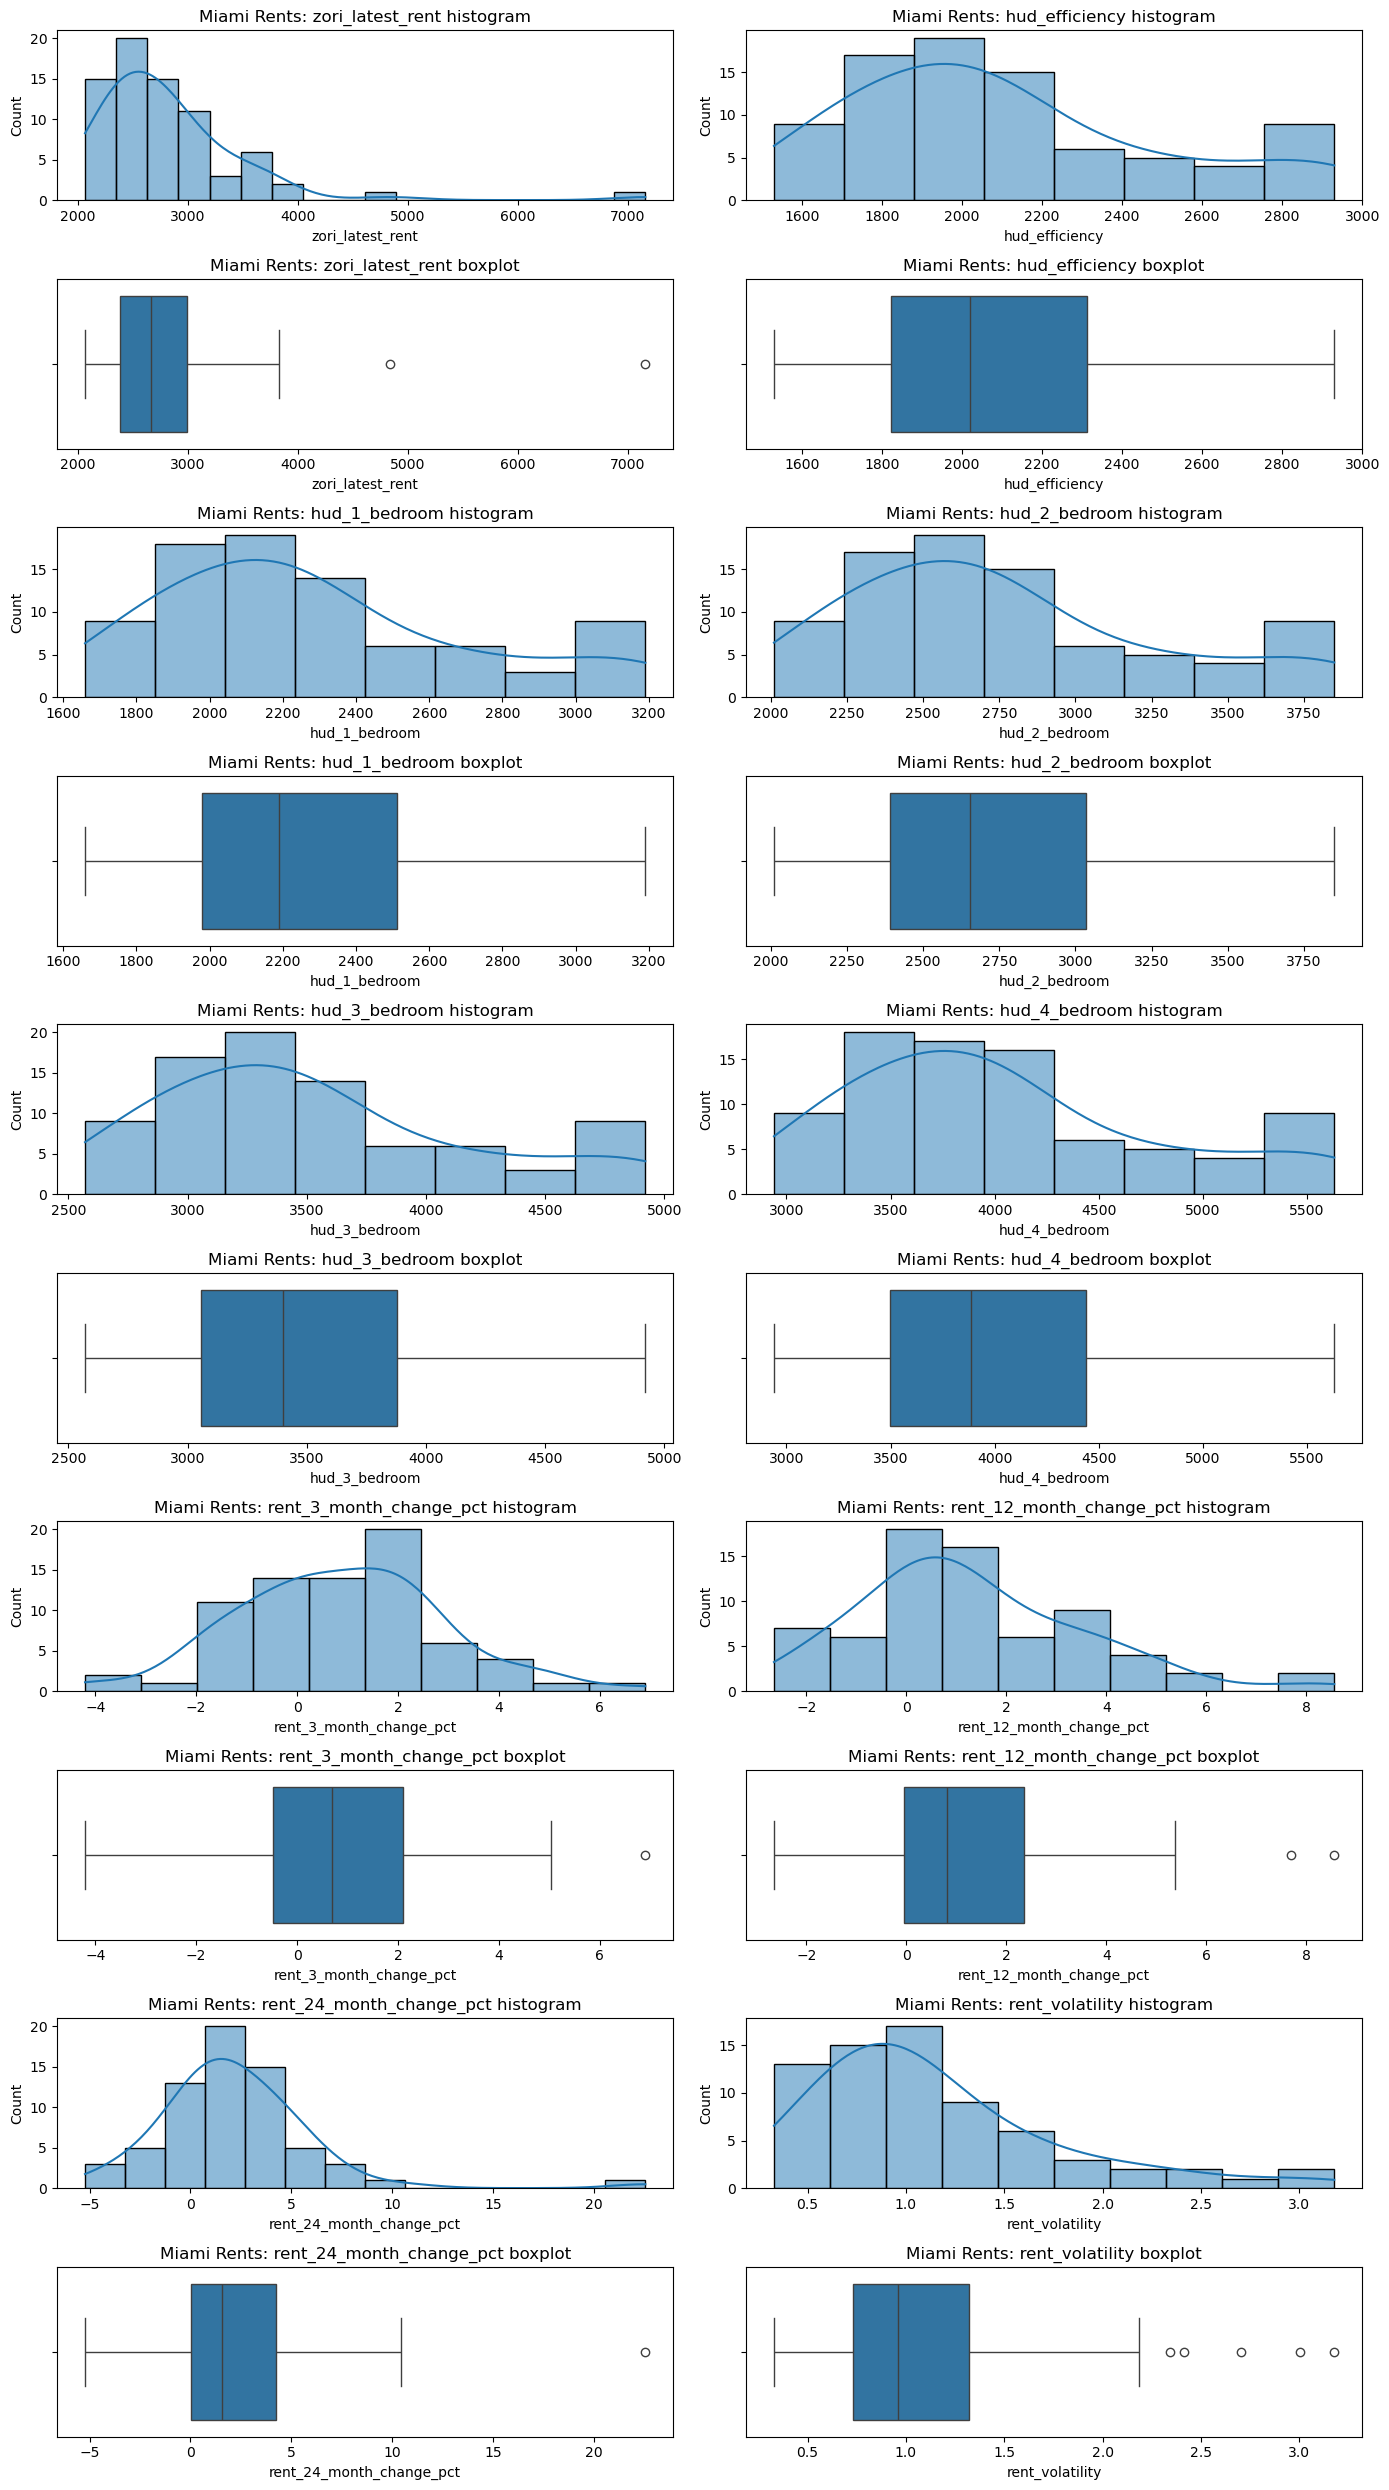

In [57]:
def profile_numeric_columns(frame):
    numeric = frame.select_dtypes(include='number')
    if numeric.empty: return pd.DataFrame()
    profile = numeric.describe().T
    profile['missing_count'], profile['zero_count'] = numeric.isna().sum(), (numeric == 0).sum()
    profile['unique_count'], profile['skewness'] = numeric.nunique(dropna=True), numeric.skew()
    profile['negative_count'] = (numeric < 0).sum()
    return profile[['count', 'missing_count', 'zero_count', 'unique_count', 'mean', 'std', 'min', 'max', 'skewness', 'negative_count']]


def plot_numeric_distributions(frame, dataset_name, excluded_columns):
    numeric_columns = [c for c in frame.select_dtypes(include='number').columns if c not in set(excluded_columns)]
    if not numeric_columns: print(f'No numeric columns to plot for {dataset_name}.'); return
    columns_per_row, rows = 2, math.ceil(len(numeric_columns) / 2)
    figure, axes = plt.subplots(rows * 2, columns_per_row, figsize=(14, rows * 5), squeeze=False)
    for index, column in enumerate(numeric_columns):
        row, column_index = (index // 2) * 2, index % 2
        values = frame[column].dropna()
        sns.histplot(values, kde=values.nunique() > 1, ax=axes[row, column_index])
        axes[row, column_index].set_title(f'{dataset_name}: {column} histogram')
        sns.boxplot(x=values, ax=axes[row + 1, column_index])
        axes[row + 1, column_index].set_title(f'{dataset_name}: {column} boxplot')
    for index in range(len(numeric_columns), rows * 2):
        row, column_index = (index // 2) * 2, index % 2
        axes[row, column_index].set_visible(False); axes[row + 1, column_index].set_visible(False)
    figure.tight_layout(); plt.show()
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} numeric profile')
    display(profile_numeric_columns(frame))
    zip_column = DATASETS[dataset_name]['zip_column']
    date_columns = [c for c in frame.columns if c[:4].isdigit() or (c.startswith('zori_') and c[5:9].isdigit())]
    plot_numeric_distributions(frame, dataset_name, [zip_column, *date_columns])

## 3. Categorical value counts and cross-dataset ZIP coverage

Value counts identify unexpected labels. Coverage comparison identifies the ZIPs shared
across all configured datasets and differences in geographic coverage. Miami Rents is a
merge of two sources, so its coverage is not an independent source of evidence.


In [58]:
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} categorical value counts')
    for column in frame.select_dtypes(exclude='number').columns:
        print(f'{column}:'); display(frame[column].value_counts(dropna=False).rename('count').to_frame())
zip_sets = {name: set(frame[DATASETS[name]['zip_column']].dropna()) for name, frame in cleaned_data.items()}
shared_zips = set.intersection(*zip_sets.values())
coverage_rows = []
for dataset_name, zip_values in zip_sets.items():
    other_zips = set().union(*(values for name, values in zip_sets.items() if name != dataset_name))
    coverage_rows.append({'dataset': dataset_name, 'zip_count': len(zip_values), 'shared_by_all_datasets': len(shared_zips), 'only_in_this_dataset': len(zip_values - other_zips)})
display(pd.DataFrame(coverage_rows))
print(f'ZIPs shared by all {len(DATASETS)} datasets: {len(shared_zips)}')
display(pd.DataFrame({'shared_zip_code': sorted(shared_zips)}))


Miami Home Values categorical value counts
RegionName:


,count
RegionName,
33177,1
33125,1
33176,1
33165,1
33193,1
33175,1
33126,1
33155,1
33135,1


RegionType:


,count
RegionType,
zip,30


StateName:


,count
StateName,
FL,30


... (43 outputs left out)

,count
zori_source_date,
2026-08,74
<NA>,10


,dataset,zip_count,shared_by_all_datasets,only_in_this_dataset
0,Miami Home Values,30,29,0
1,Miami Rental Values,29,29,0
2,Miami Transit,78,29,0
3,Miami Rents,84,29,6


ZIPs shared by all 4 datasets: 29


,shared_zip_code
0,33122
1,33125
2,33126
3,33127
4,33128
5,33129
6,33130
7,33131
8,33132
9,33133


## 4. Final data-quality checks

These checks confirm that filtered frames contain only Miami-Dade ZCTAs, ZIP codes remain strings, columns are unique, and no configured sentinel values remain.

In [59]:
quality_rows = []
for dataset_name, config in DATASETS.items():
    frame, zip_column = cleaned_data[dataset_name], config['zip_column']
    quality_rows.append({'dataset': dataset_name, 'rows': len(frame), 'zip_dtype': str(frame[zip_column].dtype), 'invalid_zip_rows': int((~frame[zip_column].isin(allowed_zips)).sum()), 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_columns': int(frame.columns.duplicated().sum()), 'sentinel_values_remaining': int(frame.isin([-666666666, -6666666666]).sum().sum())})
quality_checks = pd.DataFrame(quality_rows)
display(quality_checks)
assert (quality_checks['invalid_zip_rows'] == 0).all()
assert (quality_checks['duplicate_columns'] == 0).all()
assert (quality_checks['sentinel_values_remaining'] == 0).all()
print('All final data-quality checks passed.')

,dataset,rows,zip_dtype,invalid_zip_rows,duplicate_rows,duplicate_columns,sentinel_values_remaining
0,Miami Home Values,30,string,0,0,0,0
1,Miami Rental Values,29,string,0,0,0,0
2,Miami Transit,78,string,0,0,0,0
3,Miami Rents,84,string,0,0,0,0


All final data-quality checks passed.


## 5. Clean and explore the Miami Rents Data

Restore zero-filled Zillow rents to missing values. Use August monthly ZORI first,
then a verified August Zillow trend estimate. `zori_latest_rent` is canonical;
`latest_rent_usd` is removed after reconciliation. The remaining ZIPs stay missing,
with missing Zillow source/date metadata. HUD benchmarks never fill Zillow rents.

The EDA below retains the transit format: shape, columns, sample rows, types,
missing values, and descriptive statistics. Zeros in `rent_*_month_change_pct` are restored to missing values before profiling.


In [60]:
# Load the Miami rents dataset while preserving ZIP codes as strings.
from pathlib import Path

DATA_DIR_CANDIDATES = (Path.cwd() / "data", Path.cwd().parent / "data")
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the project's data directory. "
        "Run this notebook from the repository root or notebooks/."
    )

MIAMI_RENTS_PATH = DATA_DIR / "raw" / "miami-rents.csv"
miami_rents = clean_miami_rents(
    pd.read_csv(MIAMI_RENTS_PATH, dtype={"zip_code": "string"}, float_precision="round_trip")
)

print(f"Dataset: {MIAMI_RENTS_PATH.name}")
print(f"Shape: {miami_rents.shape}")
print()
# Keep the rent frame used by the later rent-analysis sections.
rents = miami_rents.copy().sort_values("zip_code").reset_index(drop=True)


Dataset: miami-rents.csv
Shape: (84, 25)



In [61]:
print("Column names:")
print(miami_rents.columns.tolist())
print(f"Number of columns: {miami_rents.shape[1]}")
print()

print("First 10 rows (all columns):")
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(miami_rents.head(10))
print()

print("Data types:")
display(miami_rents.dtypes.rename("dtype").to_frame())
print()

missing_summary = pd.DataFrame({
    "missing_count": miami_rents.isna().sum(),
    "missing_percent": (miami_rents.isna().mean() * 100).round(2),
})

print("Missing values by column:")
display(missing_summary)

print("Columns with missing values:")
columns_with_missing = missing_summary.loc[
    missing_summary["missing_count"] > 0
]
if columns_with_missing.empty:
    print("No columns contain missing values.")
else:
    display(columns_with_missing)

print("Descriptive statistics:")
display(miami_rents.describe(include="all").T)


Column names:
['zip_code', 'zori_2026_01', 'zori_2026_02', 'zori_2026_03', 'zori_2026_04', 'zori_2026_05', 'zori_2026_06', 'zori_2026_07', 'zori_2026_08', 'zori_latest_rent', 'hud_efficiency', 'hud_1_bedroom', 'hud_2_bedroom', 'hud_3_bedroom', 'hud_4_bedroom', 'zori_source', 'hud_source', 'rent_3_month_change_pct', 'rent_12_month_change_pct', 'rent_24_month_change_pct', 'rent_volatility', 'rent_direction', 'source', 'source_date', 'zori_source_date']
Number of columns: 25

First 10 rows (all columns):


,zip_code,zori_2026_01,zori_2026_02,zori_2026_03,zori_2026_04,zori_2026_05,zori_2026_06,zori_2026_07,zori_2026_08,zori_latest_rent,hud_efficiency,hud_1_bedroom,hud_2_bedroom,hud_3_bedroom,hud_4_bedroom,zori_source,hud_source,rent_3_month_change_pct,rent_12_month_change_pct,rent_24_month_change_pct,rent_volatility,rent_direction,source,source_date,zori_source_date
0,33010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2062.500000,2062.500000,1720,1870,2260,2890,3300,Zillow ZORI,HUD Small Area Fair Market Rents,4.484514,2.049527,3.844901,1.936998,increasing,Zillow ZORI,2026-08,2026-08
1,33012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2200.865530,2200.865530,1910,2080,2510,3210,3670,Zillow ZORI,HUD Small Area Fair Market Rents,0.607224,0.365369,1.517011,0.942041,stable,Zillow ZORI,2026-08,2026-08
2,33013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2524.444444,2524.444444,1730,1880,2270,2900,3320,Zillow ZORI,HUD Small Area Fair Market Rents,2.403093,-0.263742,NaN,2.341946,increasing,Zillow ZORI,2026-08,2026-08
3,33014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2362.098214,2362.098214,2060,2230,2700,3450,3950,Zillow ZORI,HUD Small Area Fair Market Rents,0.642410,0.425908,0.864864,0.665593,stable,Zillow ZORI,2026-08,2026-08
4,33015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2253.298920,2253.298920,2180,2370,2860,3660,4180,Zillow ZORI,HUD Small Area Fair Market Rents,0.354426,-1.320073,-0.359294,0.876467,stable,Zillow ZORI,2026-08,2026-08
5,33016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2399.226940,2399.226940,2030,2210,2670,3410,3900,Zillow ZORI,HUD Small Area Fair Market Rents,-1.569970,-1.738593,-2.137875,0.563295,decreasing,Zillow ZORI,2026-08,2026-08
6,33018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3093.716020,3093.716020,2160,2340,2830,3620,4140,Zillow ZORI,HUD Small Area Fair Market Rents,1.757754,2.180700,2.203904,0.601793,increasing,Zillow ZORI,2026-08,2026-08
7,33030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2475.000000,2475.000000,1560,1700,2050,2620,3000,Zillow ZORI,HUD Small Area Fair Market Rents,2.958976,2.106895,NaN,1.798756,increasing,Zillow ZORI,2026-08,2026-08
8,33031,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1910,2080,2510,3210,3670,<NA>,HUD Small Area Fair Market Rents,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
9,33032,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2663.805916,2663.805916,1800,1950,2360,3020,3450,Zillow ZORI,HUD Small Area Fair Market Rents,2.128525,0.981314,0.749552,1.543949,increasing,Zillow ZORI,2026-08,2026-08



Data types:


,dtype
zip_code,string[python]
zori_2026_01,float64
zori_2026_02,float64
zori_2026_03,float64
zori_2026_04,float64
zori_2026_05,float64
zori_2026_06,float64
zori_2026_07,float64
zori_2026_08,float64
zori_latest_rent,float64



Missing values by column:


,missing_count,missing_percent
zip_code,0,0.00
zori_2026_01,56,66.67
zori_2026_02,56,66.67
zori_2026_03,55,65.48
zori_2026_04,55,65.48
zori_2026_05,55,65.48
zori_2026_06,55,65.48
zori_2026_07,55,65.48
zori_2026_08,10,11.90
zori_latest_rent,10,11.90


Columns with missing values:


,missing_count,missing_percent
zori_2026_01,56,66.67
zori_2026_02,56,66.67
zori_2026_03,55,65.48
zori_2026_04,55,65.48
zori_2026_05,55,65.48
zori_2026_06,55,65.48
zori_2026_07,55,65.48
zori_2026_08,10,11.90
zori_latest_rent,10,11.90
zori_source,10,11.90


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
zip_code,84,84,33010,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zori_2026_01,28.0,NaN,NaN,NaN,2808.393565,484.297892,2122.036267,2428.757616,2684.581859,3291.765836,3856.182758
zori_2026_02,28.0,NaN,NaN,NaN,2815.328313,484.831759,2137.60944,2431.364211,2677.49771,3277.22152,3866.957877
zori_2026_03,29.0,NaN,NaN,NaN,2824.940432,480.865278,2107.030074,2453.794389,2722.983826,3243.497895,3846.303678
zori_2026_04,29.0,NaN,NaN,NaN,2836.546122,485.128576,2100.077129,2462.111969,2731.433534,3190.257233,3859.062284
zori_2026_05,29.0,NaN,NaN,NaN,2838.32459,492.24909,2097.444334,2384.495322,2765.197526,3174.586655,3834.779849
zori_2026_06,29.0,NaN,NaN,NaN,2837.688464,491.790093,2106.902143,2376.798407,2744.2437,3179.622522,3831.772434
zori_2026_07,29.0,NaN,NaN,NaN,2850.054517,486.158263,2127.589713,2407.033392,2768.770342,3289.0302,3813.44959
zori_2026_08,74.0,NaN,NaN,NaN,2817.263804,722.147531,2062.5,2376.622289,2661.652958,2986.303105,7161.927609
zori_latest_rent,74.0,NaN,NaN,NaN,2817.263804,722.147531,2062.5,2376.622289,2661.652958,2986.303105,7161.927609


## 6. Canonical rent levels and benchmark checks

Check canonical latest rent against August, report missing Zillow coverage, and verify
that its source and date exist only when rent is available. HUD bedroom benchmarks
remain separate measures. Model inputs use the numerical 3-month change; direction
labels are reserved for user explanations.


,count,mean,std,min,25%,50%,75%,max
zori_latest_rent,74.0,2817.26,722.15,2062.5,2376.62,2661.65,2986.3,7161.93
hud_efficiency,84.0,2102.50,387.89,1530.0,1822.50,2020.00,2312.5,2930.00
hud_1_bedroom,84.0,2284.76,422.15,1660.0,1980.00,2190.00,2512.5,3190.00
hud_2_bedroom,84.0,2761.67,510.35,2010.0,2390.00,2655.00,3035.0,3850.00
hud_3_bedroom,84.0,3530.12,652.45,2570.0,3057.50,3400.00,3877.5,4920.00
hud_4_bedroom,84.0,4038.81,747.39,2940.0,3495.00,3885.00,4437.5,5630.00


Canonical Zillow rent available: 74/84 ZIPs.
ZIPs without Zillow rent (HUD benchmarks remain separate):


,zip_code,hud_2_bedroom,zori_source,zori_source_date
8,33031,2510,<NA>,<NA>
13,33039,2560,<NA>,<NA>
17,33090,2560,<NA>,<NA>
18,33101,2560,<NA>,<NA>
19,33109,3690,<NA>,<NA>
20,33114,2560,<NA>,<NA>
21,33116,2560,<NA>,<NA>
23,33124,2560,<NA>,<NA>
53,33158,3290,<NA>,<NA>
78,33187,3050,<NA>,<NA>


Canonical latest vs. zori_2026_08: 74 comparable ZIPs; 0 differences above $0.01.
Nonpositive rent observations:


,nonpositive_observations
zori_latest_rent,0
hud_efficiency,0
hud_1_bedroom,0
hud_2_bedroom,0
hud_3_bedroom,0
hud_4_bedroom,0
zori_2026_01,0
zori_2026_02,0
zori_2026_03,0
zori_2026_04,0


HUD bedroom-order checks: 84 complete ZIPs; 0 decreasing benchmark sequences.


,zip_code,hud_efficiency,hud_1_bedroom,hud_2_bedroom,hud_3_bedroom,hud_4_bedroom


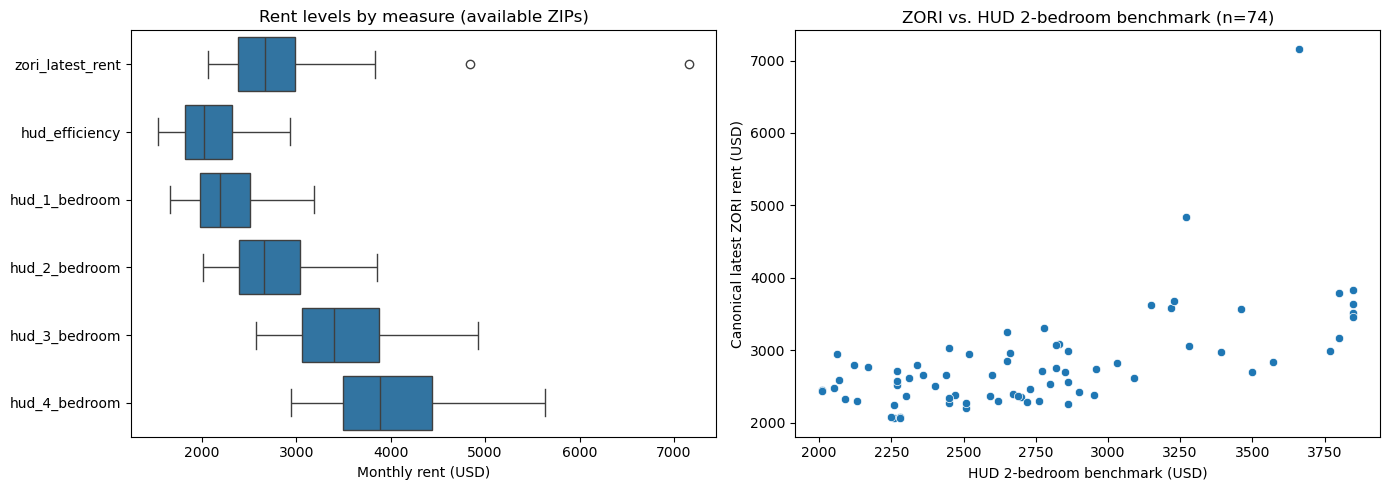

In [62]:
zori_months = sorted(column for column in rents if pd.Series([column]).str.fullmatch(r'zori_\d{4}_\d{2}').iloc[0])
hud_columns = ['hud_efficiency', 'hud_1_bedroom', 'hud_2_bedroom', 'hud_3_bedroom', 'hud_4_bedroom']
level_columns = ['zori_latest_rent', *hud_columns]
display(rents[level_columns].describe().T.round(2))

assert rents['zip_code'].dtype.name == 'string'
assert rents['zip_code'].is_unique
assert 'latest_rent_usd' not in rents
pd.testing.assert_series_equal(rents['zori_latest_rent'], rents['zori_2026_08'], check_names=False)
has_zillow_rent = rents['zori_latest_rent'].notna()
assert rents.loc[has_zillow_rent, 'zori_source'].eq('Zillow ZORI').all()
assert rents.loc[has_zillow_rent, 'zori_source_date'].eq('2026-08').all()
assert rents.loc[~has_zillow_rent, ['zori_source', 'zori_source_date']].isna().all().all()
print(f'Canonical Zillow rent available: {int(has_zillow_rent.sum())}/{len(rents)} ZIPs.')
print('ZIPs without Zillow rent (HUD benchmarks remain separate):')
display(rents.loc[~has_zillow_rent, ['zip_code', 'hud_2_bedroom', 'zori_source', 'zori_source_date']])

last_month = zori_months[-1]
month_pair = rents.dropna(subset=['zori_latest_rent', last_month])
month_mismatch_count = int((~np.isclose(month_pair['zori_latest_rent'], month_pair[last_month], rtol=0, atol=0.01)).sum())
print(f'Canonical latest vs. {last_month}: {len(month_pair)} comparable ZIPs; {month_mismatch_count} differences above $0.01.')

nonpositive_rents = rents[level_columns + zori_months].le(0).sum().rename('nonpositive_observations')
print('Nonpositive rent observations:')
display(nonpositive_rents.to_frame())
hud_complete = rents[hud_columns].notna().all(axis=1)
hud_order_issues = hud_complete & rents[hud_columns].diff(axis=1).iloc[:, 1:].lt(0).any(axis=1)
print(f'HUD bedroom-order checks: {int(hud_complete.sum())} complete ZIPs; {int(hud_order_issues.sum())} decreasing benchmark sequences.')
display(rents.loc[hud_order_issues, ['zip_code', *hud_columns]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
level_long = rents[['zori_latest_rent', *hud_columns]].melt(var_name='measure', value_name='monthly_rent_usd').dropna()
sns.boxplot(data=level_long, x='monthly_rent_usd', y='measure', ax=axes[0])
axes[0].set(title='Rent levels by measure (available ZIPs)', xlabel='Monthly rent (USD)', ylabel='')
benchmark_pair = rents.dropna(subset=['zori_latest_rent', 'hud_2_bedroom'])
sns.scatterplot(data=benchmark_pair, x='hud_2_bedroom', y='zori_latest_rent', ax=axes[1])
axes[1].set(title=f'ZORI vs. HUD 2-bedroom benchmark (n={len(benchmark_pair)})', xlabel='HUD 2-bedroom benchmark (USD)', ylabel='Canonical latest ZORI rent (USD)')
fig.tight_layout()
plt.show()


## 7. Growth, direction, volatility, and unusual values

Growth fields report percentage change across 3, 12, and 24 months. `rent_volatility`
measures the standard deviation of monthly percentage changes over 12 months (percentage
points). Check direction labels against the generating script's 3-month thresholds:
above +1% is increasing, below −1% is decreasing, otherwise stable. Each statistic uses
its own available observations. IQR flags identify values for review and do not remove rows.

Direction consistency is checked only where both numerical growth and a direction
label are available. Missing growth does not establish a stable trend.


,count,mean,std,min,25%,50%,75%,max
rent_3_month_change_pct,74.0,0.852,2.022,-4.203,-0.473,0.699,2.102,6.899
rent_12_month_change_pct,70.0,1.300,2.257,-2.650,-0.057,0.807,2.347,8.559
rent_24_month_change_pct,66.0,2.186,3.874,-5.222,0.055,1.544,4.237,22.553
rent_volatility,70.0,1.139,0.624,0.329,0.731,0.960,1.322,3.177


,zip_count,percent_of_all_zips
rent_direction,,
increasing,36,42.9
stable,25,29.8
decreasing,13,15.5
Missing,10,11.9


Direction-label mismatches: 0
Negative volatility observations: 0


,zip_code,rent_3_month_change_pct,rent_direction


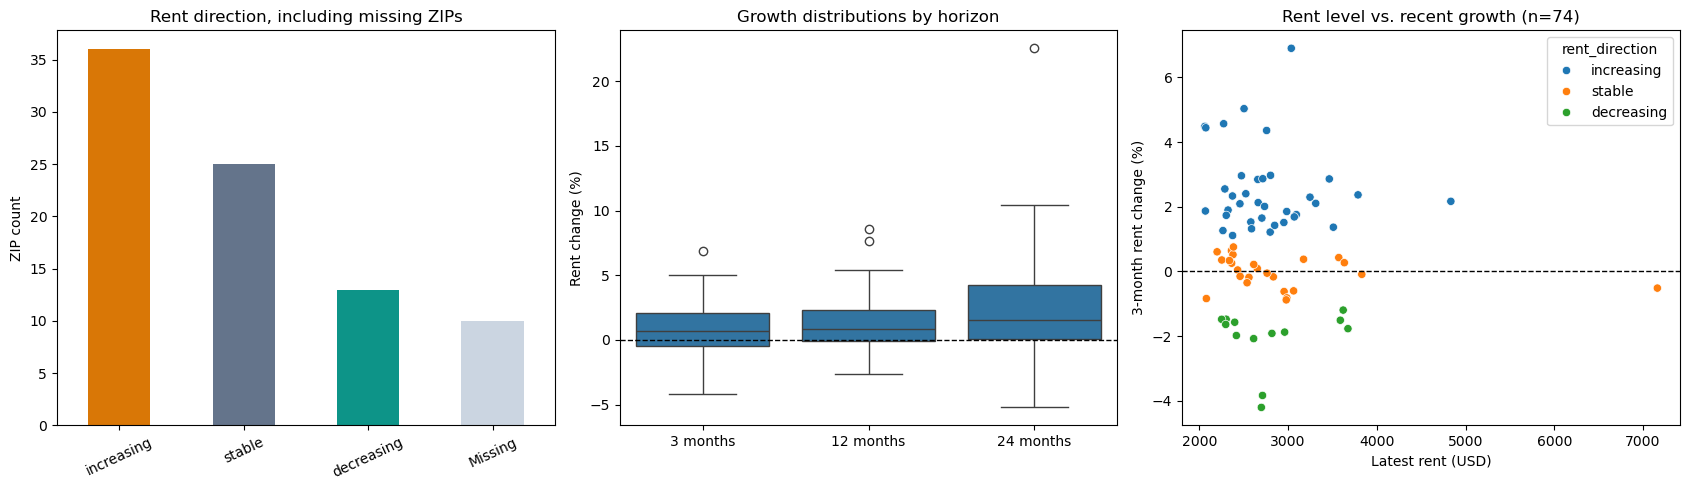

IQR review flags: 11 observations across 9 ZIPs; no rows removed.


,zip_code,column,value,lower_fence,upper_fence
0,33149,zori_latest_rent,7161.928,1462.101,3900.824
1,33154,zori_latest_rent,4834.762,1462.101,3900.824
2,33055,rent_3_month_change_pct,6.899,-4.336,5.965
3,33056,rent_12_month_change_pct,7.686,-3.664,5.953
4,33185,rent_12_month_change_pct,8.559,-3.664,5.953
5,33055,rent_24_month_change_pct,22.553,-6.218,10.510
6,33013,rent_volatility,2.342,-0.155,2.209
7,33055,rent_volatility,3.002,-0.155,2.209
8,33144,rent_volatility,2.413,-0.155,2.209
9,33147,rent_volatility,2.705,-0.155,2.209


In [63]:
growth_columns = ['rent_3_month_change_pct', 'rent_12_month_change_pct', 'rent_24_month_change_pct']
trend_columns = [*growth_columns, 'rent_volatility']
display(rents[trend_columns].describe().T.round(3))
direction_order = ['increasing', 'stable', 'decreasing', 'Missing']
direction_counts = rents['rent_direction'].fillna('Missing').value_counts().reindex(direction_order, fill_value=0)
display(pd.DataFrame({
    'zip_count': direction_counts,
    'percent_of_all_zips': direction_counts.div(len(rents)).mul(100).round(1),
}))
expected_direction = pd.Series(pd.NA, index=rents.index, dtype='string')
known_growth = rents['rent_3_month_change_pct'].notna() & rents['rent_direction'].notna()
expected_direction.loc[known_growth] = np.select(
    [rents.loc[known_growth, 'rent_3_month_change_pct'].gt(1),
     rents.loc[known_growth, 'rent_3_month_change_pct'].lt(-1)],
    ['increasing', 'decreasing'], default='stable',
)
direction_issues = rents['rent_direction'].astype('string').fillna('Missing').ne(expected_direction.fillna('Missing'))
print(f'Direction-label mismatches: {int(direction_issues.sum())}')
print(f'Negative volatility observations: {int(rents["rent_volatility"].lt(0).sum())}')
display(rents.loc[direction_issues, ['zip_code', 'rent_3_month_change_pct', 'rent_direction']])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
direction_counts.plot.bar(ax=axes[0], color=['#d97706', '#64748b', '#0d9488', '#cbd5e1'], rot=25)
axes[0].set(title='Rent direction, including missing ZIPs', ylabel='ZIP count', xlabel='')
growth_long = rents[growth_columns].rename(columns=dict(zip(growth_columns, ['3 months', '12 months', '24 months']))).melt(var_name='period', value_name='change_pct').dropna()
sns.boxplot(data=growth_long, x='period', y='change_pct', ax=axes[1])
axes[1].axhline(0, color='black', linewidth=1, linestyle='--')
axes[1].set(title='Growth distributions by horizon', xlabel='', ylabel='Rent change (%)')
scatter_rows = rents.dropna(subset=['zori_latest_rent', 'rent_3_month_change_pct', 'rent_direction'])
sns.scatterplot(data=scatter_rows, x='zori_latest_rent', y='rent_3_month_change_pct', hue='rent_direction', ax=axes[2])
axes[2].axhline(0, color='black', linewidth=1, linestyle='--')
axes[2].set(title=f'Rent level vs. recent growth (n={len(scatter_rows)})', xlabel='Latest rent (USD)', ylabel='3-month rent change (%)')
fig.tight_layout()
plt.show()

outlier_rows = []
for column in ['zori_latest_rent', *trend_columns]:
    observed = rents[column].dropna()
    q1, q3 = observed.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = rents.loc[rents[column].lt(lower) | rents[column].gt(upper), ['zip_code', column]]
    for _, row in flagged.iterrows():
        outlier_rows.append({'zip_code': row['zip_code'], 'column': column, 'value': row[column], 'lower_fence': lower, 'upper_fence': upper})
outlier_review = pd.DataFrame(outlier_rows, columns=['zip_code', 'column', 'value', 'lower_fence', 'upper_fence'])
print(f'IQR review flags: {len(outlier_review)} observations across {outlier_review["zip_code"].nunique()} ZIPs; no rows removed.')
display(outlier_review.round(3))


## 8. Monthly rent paths and correlations

Plot January–August ZORI coverage by month. Use only ZIPs observed in **every** month for
the median and interquartile band so changing coverage does not change the comparison
cohort. This is an unweighted summary of ZIP estimates, not an official Miami rent index.

Correlations use pairwise complete observations with at least 3 ZIPs per pair. Show the
sample size alongside each coefficient. Use the canonical latest-rent field and exclude
monthly ZORI columns to reduce repeated measures. These exploratory associations do not
show causation; HUD bedroom benchmarks are also strongly related by construction.


,month,available_zips,balanced_cohort_zips,balanced_median_usd,balanced_q25_usd,balanced_q75_usd
0,2026-01-01,28,28,2684.58,2428.76,3291.77
1,2026-02-01,28,28,2677.50,2431.36,3277.22
2,2026-03-01,29,28,2713.10,2427.27,3249.55
3,2026-04-01,29,28,2725.15,2438.38,3206.37
4,2026-05-01,29,28,2723.47,2380.25,3191.94
5,2026-06-01,29,28,2729.48,2376.22,3201.46
6,2026-07-01,29,28,2745.47,2400.11,3290.40
7,2026-08-01,74,28,2767.25,2439.88,3263.69


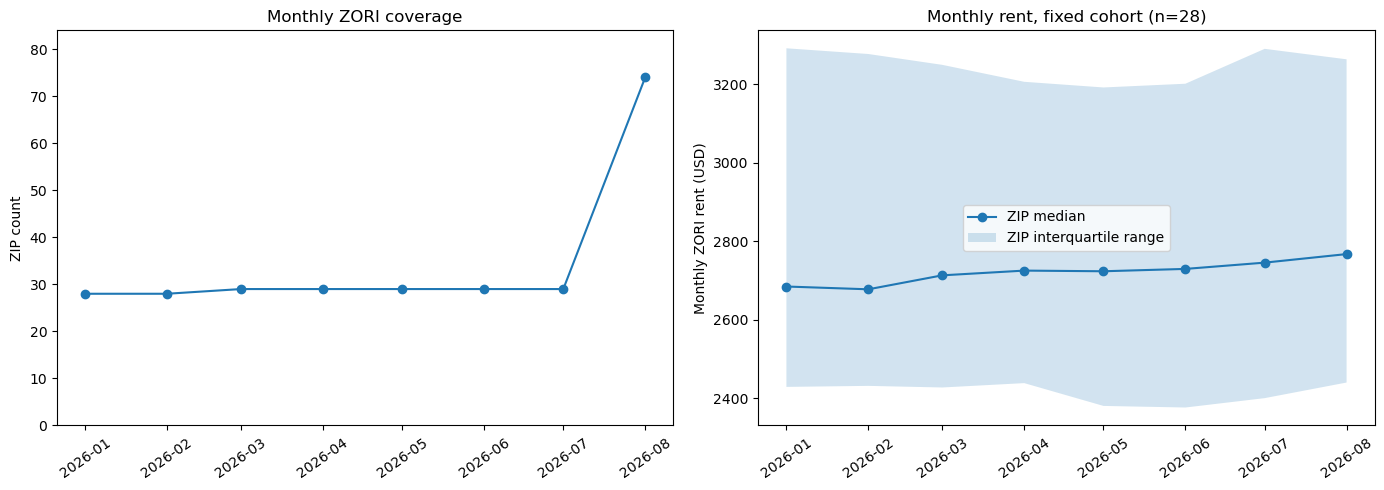

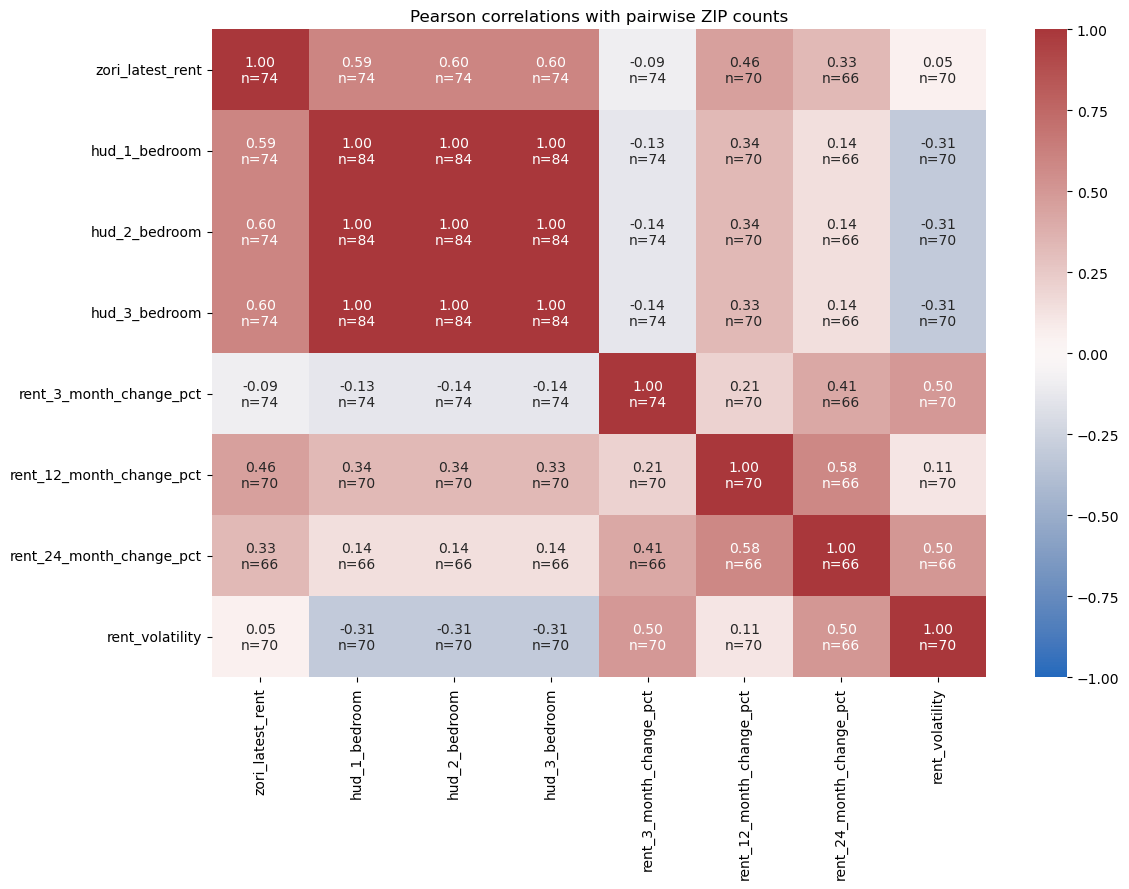

In [64]:
month_dates = pd.to_datetime([column.removeprefix('zori_').replace('_', '-') for column in zori_months])
monthly_coverage = rents[zori_months].notna().sum()
balanced_monthly = rents.dropna(subset=zori_months)[zori_months]
monthly_summary = pd.DataFrame({
    'month': month_dates,
    'available_zips': monthly_coverage.to_numpy(),
    'balanced_cohort_zips': len(balanced_monthly),
    'balanced_median_usd': balanced_monthly.median().to_numpy(),
    'balanced_q25_usd': balanced_monthly.quantile(0.25).to_numpy(),
    'balanced_q75_usd': balanced_monthly.quantile(0.75).to_numpy(),
})
display(monthly_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(month_dates, monthly_coverage.to_numpy(), marker='o')
axes[0].set(title='Monthly ZORI coverage', ylabel='ZIP count', ylim=(0, len(rents)))
if len(balanced_monthly):
    axes[1].plot(month_dates, monthly_summary['balanced_median_usd'], marker='o', label='ZIP median')
    axes[1].fill_between(month_dates, monthly_summary['balanced_q25_usd'], monthly_summary['balanced_q75_usd'], alpha=0.2, label='ZIP interquartile range')
    axes[1].legend()
axes[1].set(title=f'Monthly rent, fixed cohort (n={len(balanced_monthly)})', ylabel='Monthly ZORI rent (USD)')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()

correlation_columns = ['zori_latest_rent', 'hud_1_bedroom', 'hud_2_bedroom', 'hud_3_bedroom', *trend_columns]
correlation_data = rents[correlation_columns]
correlations = correlation_data.corr(min_periods=3)
observed_flags = correlation_data.notna().astype(int)
pair_counts = observed_flags.T.dot(observed_flags)
annotations = correlations.copy().astype(object)
for row in correlations.index:
    for column in correlations.columns:
        value = correlations.loc[row, column]
        annotations.loc[row, column] = f'{value:.2f}\nn={pair_counts.loc[row, column]}' if pd.notna(value) else ''
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlations, mask=correlations.isna(), annot=annotations, fmt='', cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Pearson correlations with pairwise ZIP counts')
fig.tight_layout()
plt.show()


## 9. Findings and implications for cleaning

The summary below is calculated from the current CSV. Preserve missing observations,
review flagged values against their sources, and avoid feeding duplicate rent measures
into a model without an explicit feature choice. Benchmark comparisons need compatible
periods and housing definitions; the merged file records trend dates but does not record
a HUD benchmark year. No affordability conclusion follows from these columns alone.


In [65]:
latest_values = rents['zori_latest_rent'].dropna()
latest_count = int(rents['zori_latest_rent'].notna().sum())
dates_observed = ', '.join(sorted(rents['zori_source_date'].dropna().unique()))
findings = [
    f'**Coverage:** {len(rents)} unique ZIPs; HUD 2-bedroom benchmarks for {int(rents["hud_2_bedroom"].notna().sum())}; canonical Zillow rents for {latest_count}.',
    f'**Canonical latest rents:** median ${latest_values.median():,.2f}, ranging from ${latest_values.min():,.2f} to ${latest_values.max():,.2f} across observed ZIPs. Zillow observation month(s): {dates_observed}.',
    f'**Direction:** {direction_counts["increasing"]} increasing, {direction_counts["stable"]} stable, {direction_counts["decreasing"]} decreasing, and {direction_counts["Missing"]} missing.',
    f'**Growth coverage after restoring missing values:** {int(rents["rent_12_month_change_pct"].notna().sum())} ZIPs have a stored 12-month change; {int(rents["rent_24_month_change_pct"].notna().sum())} have a stored 24-month change; {int(rents["rent_volatility"].notna().sum())} have volatility.',
    f'**Canonical-field consistency:** latest ZORI vs. August has {month_mismatch_count} differences above $0.01; the duplicate latest_rent_usd field has been removed.',
    f'**Quality review:** {int(nonpositive_rents.sum())} nonpositive rent values, {int(hud_order_issues.sum())} HUD ordering issues, {int(direction_issues.sum())} direction-label mismatches, and {len(outlier_review)} IQR flags. Flags are retained for review.',
    f'**Monthly cohort:** {len(balanced_monthly)} ZIPs have all {len(zori_months)} monthly observations. Monthly plots cover this smaller cohort, not all ZIPs with trend data.',
    '**Cleaning choice:** keep unavailable data missing; use zori_latest_rent and numerical growth as model features; keep identifiers, sources, dates, and rent_direction out of model inputs.',
]
display(Markdown('\n\n'.join(f'- {finding}' for finding in findings)))


- **Coverage:** 84 unique ZIPs; HUD 2-bedroom benchmarks for 84; canonical Zillow rents for 74.

- **Canonical latest rents:** median $2,661.65, ranging from $2,062.50 to $7,161.93 across observed ZIPs. Zillow observation month(s): 2026-08.

- **Direction:** 36 increasing, 25 stable, 13 decreasing, and 10 missing.

- **Growth coverage after restoring missing values:** 70 ZIPs have a stored 12-month change; 66 have a stored 24-month change; 70 have volatility.

- **Canonical-field consistency:** latest ZORI vs. August has 0 differences above $0.01; the duplicate latest_rent_usd field has been removed.

- **Quality review:** 0 nonpositive rent values, 0 HUD ordering issues, 0 direction-label mismatches, and 11 IQR flags. Flags are retained for review.

- **Monthly cohort:** 28 ZIPs have all 8 monthly observations. Monthly plots cover this smaller cohort, not all ZIPs with trend data.

- **Cleaning choice:** keep unavailable data missing; use zori_latest_rent and numerical growth as model features; keep identifiers, sources, dates, and rent_direction out of model inputs.

## 10. Model inputs, metadata, and explanations

Use an explicit numerical feature list. January–August ZORI columns are dropped
from the cleaned export and excluded from modeling. ZIP codes remain string
identifiers, and rent_direction is retained only for user explanations. The next
sections drop the specified columns and prepare median-imputed model inputs.


In [66]:
rent_model_features = rents.loc[:, MODEL_FEATURE_COLUMNS].copy()
rent_metadata = rents.loc[:, METADATA_COLUMNS].copy()
rent_explanations = rents.loc[:, ['zip_code', *EXPLANATION_COLUMNS]].copy()
assert not set(METADATA_COLUMNS + EXPLANATION_COLUMNS) & set(rent_model_features.columns)
assert 'latest_rent_usd' not in rent_model_features
assert not set(EXCLUDED_MONTH_COLUMNS + ['zori_2026_08']) & set(rent_model_features.columns)
assert rent_model_features.select_dtypes(include='number').shape[1] == len(MODEL_FEATURE_COLUMNS)
print('Numerical model features:')
display(pd.DataFrame({'model_feature': MODEL_FEATURE_COLUMNS}))
print('Identifiers and metadata:')
display(rent_metadata.head())
print('User explanations:')
display(rent_explanations.head())


Numerical model features:


,model_feature
0,zori_latest_rent
1,hud_efficiency
2,hud_1_bedroom
3,hud_2_bedroom
4,hud_3_bedroom
5,hud_4_bedroom
6,rent_3_month_change_pct
7,rent_12_month_change_pct
8,rent_24_month_change_pct
9,rent_volatility


Identifiers and metadata:


,zip_code,zori_source,hud_source,source,source_date,zori_source_date
0,33010,Zillow ZORI,HUD Small Area Fair Market Rents,Zillow ZORI,2026-08,2026-08
1,33012,Zillow ZORI,HUD Small Area Fair Market Rents,Zillow ZORI,2026-08,2026-08
2,33013,Zillow ZORI,HUD Small Area Fair Market Rents,Zillow ZORI,2026-08,2026-08
3,33014,Zillow ZORI,HUD Small Area Fair Market Rents,Zillow ZORI,2026-08,2026-08
4,33015,Zillow ZORI,HUD Small Area Fair Market Rents,Zillow ZORI,2026-08,2026-08


User explanations:


,zip_code,rent_direction
0,33010,increasing
1,33012,stable
2,33013,increasing
3,33014,stable
4,33015,stable


## 11. Audit zeros and drop columns

Audit every numeric rent column, restore any remaining zero placeholders to NaN,
and drop `zori_2026_01` through `zori_2026_08`, `zori_source`, `hud_source`, `source`, `zori_source_date`,
and `source_date`. Keep ZIPs as strings. All monthly ZORI columns are removed from the export
and excluded from the model feature list. Only the five fields named below
receive median imputation.


In [67]:
zero_audit = rents.select_dtypes(include='number').eq(0).sum().rename('zeros_before').to_frame()
rent_table = prepare_rent_table(rents)
zero_audit['zeros_after'] = rent_table.select_dtypes(include='number').eq(0).sum().reindex(zero_audit.index)
zero_audit['dropped'] = zero_audit.index.isin(DROP_COLUMNS)
display(zero_audit)
assert not rent_table.select_dtypes(include='number').eq(0).any().any()
assert not set(DROP_COLUMNS) & set(rent_table.columns)
assert not set(EXCLUDED_MONTH_COLUMNS) & set(rent_table.columns)
assert not set(EXCLUDED_MONTH_COLUMNS) & set(MODEL_FEATURE_COLUMNS)
assert rent_table['zip_code'].dtype.name == 'string'
print('Dropped columns:', ', '.join(DROP_COLUMNS))
print('Monthly fields excluded from models:', ', '.join(EXCLUDED_MONTH_COLUMNS))


,zeros_before,zeros_after,dropped
zori_2026_01,0,NaN,True
zori_2026_02,0,NaN,True
zori_2026_03,0,NaN,True
zori_2026_04,0,NaN,True
zori_2026_05,0,NaN,True
zori_2026_06,0,NaN,True
zori_2026_07,0,NaN,True
zori_2026_08,0,NaN,True
zori_latest_rent,0,0.0,False
hud_efficiency,0,0.0,False


Dropped columns: zori_2026_01, zori_2026_02, zori_2026_03, zori_2026_04, zori_2026_05, zori_2026_06, zori_2026_07, zori_2026_08, zori_source, hud_source, source, zori_source_date, source_date
Monthly fields excluded from models: zori_2026_01, zori_2026_02, zori_2026_03, zori_2026_04, zori_2026_05, zori_2026_06, zori_2026_07, zori_2026_08


## 12. Median imputation for model inputs

Impute `zori_latest_rent`, the 3-, 12-, and 24-month percentage-change fields, and
`rent_volatility`. Preserve observed values. The export below uses medians fitted
on the complete dataset as a descriptive snapshot. For model evaluation, split
`rent_table` first, call `fit_rent_imputer(train_rows)`, and reuse that fitted imputer
with `impute_rent_table` on training, validation, and test rows. Do not evaluate a
model by splitting the already imputed full-dataset CSV.


In [68]:
rent_imputer = fit_rent_imputer(rent_table)
miami_rents_cleaned = impute_rent_table(rent_table, rent_imputer)
imputation_summary = pd.DataFrame({
    'missing_before': rent_table[MEDIAN_IMPUTE_COLUMNS].isna().sum(),
    'median_used': pd.Series(rent_imputer.statistics_, index=MEDIAN_IMPUTE_COLUMNS),
    'missing_after': miami_rents_cleaned[MEDIAN_IMPUTE_COLUMNS].isna().sum(),
})
imputation_summary['median_imputed_count'] = (
    imputation_summary['missing_before'] - imputation_summary['missing_after']
)
imputation_summary['imputed_percent'] = (
    imputation_summary['median_imputed_count'].div(len(rent_table)).mul(100).round(2)
)
display(imputation_summary[[
    'missing_before', 'median_used', 'median_imputed_count', 'imputed_percent', 'missing_after',
]])
print(f"Columns with median-filled values: {int(imputation_summary['median_imputed_count'].gt(0).sum())}")
print(f"Total values filled with medians: {int(imputation_summary['median_imputed_count'].sum())}")
print('These are filled cells in existing columns; no new CSV columns are added.')
assert miami_rents_cleaned[MEDIAN_IMPUTE_COLUMNS].notna().all().all()
for column in MEDIAN_IMPUTE_COLUMNS:
    observed = rent_table[column].notna()
    pd.testing.assert_series_equal(
        miami_rents_cleaned.loc[observed, column], rent_table.loc[observed, column],
    )
rent_model_features = miami_rents_cleaned.loc[:, MODEL_FEATURE_COLUMNS].copy()
assert rent_model_features.notna().all().all()
assert not set(EXCLUDED_MONTH_COLUMNS + DROP_COLUMNS + ['zip_code', 'rent_direction']) & set(rent_model_features.columns)
print(f'Model matrix: {rent_model_features.shape[0]} ZIPs, {rent_model_features.shape[1]} numeric features.')


,missing_before,median_used,median_imputed_count,imputed_percent,missing_after
zori_latest_rent,10,2661.652958,10,11.90,0
rent_3_month_change_pct,10,0.699483,10,11.90,0
rent_12_month_change_pct,14,0.806629,14,16.67,0
rent_24_month_change_pct,18,1.544480,18,21.43,0
rent_volatility,14,0.959667,14,16.67,0


Columns with median-filled values: 5
Total values filled with medians: 66
These are filled cells in existing columns; no new CSV columns are added.
Model matrix: 84 ZIPs, 10 numeric features.


## 13. Fill missing rent direction from the three-month change

Use the existing median-imputed `rent_3_month_change_pct`: above +1% is increasing,
below −1% is decreasing, and −1% through +1% (inclusive) is stable. A missing change
leaves direction missing. Preserve existing direction labels. Labels filled from an
imputed change are estimates, and `rent_direction` remains an explanation field
excluded from model features.


In [69]:
missing_direction = miami_rents_cleaned['rent_direction'].isna()
miami_rents_cleaned = fill_missing_rent_direction(miami_rents_cleaned)
direction_fill_summary = pd.DataFrame({
    'missing_before': [int(missing_direction.sum())],
    'labels_filled': [int(missing_direction.sum() - miami_rents_cleaned['rent_direction'].isna().sum())],
    'missing_after': [int(miami_rents_cleaned['rent_direction'].isna().sum())],
}, index=['rent_direction'])
display(direction_fill_summary)
print('New direction labels derived from the imputed three-month change:')
display(miami_rents_cleaned.loc[
    missing_direction, ['zip_code', 'rent_3_month_change_pct', 'rent_direction'],
])
print('Final direction counts:')
display(miami_rents_cleaned['rent_direction'].value_counts(dropna=False).rename('zip_count').to_frame())
print('Missing values in the complete export:')
display(miami_rents_cleaned.isna().sum().rename('missing_count').to_frame())
assert not miami_rents_cleaned.isna().any().any()
rent_explanations = miami_rents_cleaned[['zip_code', 'rent_direction']].copy()


,missing_before,labels_filled,missing_after
rent_direction,10,10,0


New direction labels derived from the imputed three-month change:


,zip_code,rent_3_month_change_pct,rent_direction
8,33031,0.699483,stable
13,33039,0.699483,stable
17,33090,0.699483,stable
18,33101,0.699483,stable
19,33109,0.699483,stable
20,33114,0.699483,stable
21,33116,0.699483,stable
23,33124,0.699483,stable
53,33158,0.699483,stable
78,33187,0.699483,stable


Final direction counts:


,zip_count
rent_direction,
increasing,36
stable,35
decreasing,13


Missing values in the complete export:


,missing_count
zip_code,0
zori_latest_rent,0
hud_efficiency,0
hud_1_bedroom,0
hud_2_bedroom,0
hud_3_bedroom,0
hud_4_bedroom,0
rent_3_month_change_pct,0
rent_12_month_change_pct,0
rent_24_month_change_pct,0


## 14. Save the cleaned dataset — outlier treatment pending

Outliers remain unchanged. Save the complete dataset as `Miami-rents-cleaned.csv`
only after verifying that every column has zero missing values. Monthly ZORI columns
remain removed; the five imputed fields and direction labels are complete. The
original `miami-rents.csv` retains observed-data coverage.


In [70]:
CLEANED_RENT_PATH = NEW_DATA_DIR / 'Miami-rents-cleaned.csv'
assert len(miami_rents_cleaned) == len(rents)
assert miami_rents_cleaned['zip_code'].is_unique
assert miami_rents_cleaned['zip_code'].str.fullmatch(r'[0-9]{5}').all()
assert not miami_rents_cleaned.isna().any().any()
assert miami_rents_cleaned['rent_direction'].isin(['increasing', 'decreasing', 'stable']).all()
miami_rents_cleaned.to_csv(CLEANED_RENT_PATH, index=False, na_rep='', lineterminator='\n')
print(f'Saved {len(miami_rents_cleaned)} ZIP rows and {len(miami_rents_cleaned.columns)} columns to {CLEANED_RENT_PATH}')
print(f'Total missing values: {miami_rents_cleaned.isna().sum().sum()}')
print('Outliers retained; treatment pending.')
print('First 10 rows (all columns):')
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(miami_rents_cleaned.head(10))


Saved 84 ZIP rows and 12 columns to /Users/joanachoong/Flow-1B-responsible-ai-prototype-for-personalized-neighborhood-recommendations/data/cleaned/new/Miami-rents-cleaned.csv
Total missing values: 0
Outliers retained; treatment pending.
First 10 rows (all columns):


,zip_code,zori_latest_rent,hud_efficiency,hud_1_bedroom,hud_2_bedroom,hud_3_bedroom,hud_4_bedroom,rent_3_month_change_pct,rent_12_month_change_pct,rent_24_month_change_pct,rent_volatility,rent_direction
0,33010,2062.500000,1720,1870,2260,2890,3300,4.484514,2.049527,3.844901,1.936998,increasing
1,33012,2200.865530,1910,2080,2510,3210,3670,0.607224,0.365369,1.517011,0.942041,stable
2,33013,2524.444444,1730,1880,2270,2900,3320,2.403093,-0.263742,1.544480,2.341946,increasing
3,33014,2362.098214,2060,2230,2700,3450,3950,0.642410,0.425908,0.864864,0.665593,stable
4,33015,2253.298920,2180,2370,2860,3660,4180,0.354426,-1.320073,-0.359294,0.876467,stable
5,33016,2399.226940,2030,2210,2670,3410,3900,-1.569970,-1.738593,-2.137875,0.563295,decreasing
6,33018,3093.716020,2160,2340,2830,3620,4140,1.757754,2.180700,2.203904,0.601793,increasing
7,33030,2475.000000,1560,1700,2050,2620,3000,2.958976,2.106895,1.544480,1.798756,increasing
8,33031,2661.652958,1910,2080,2510,3210,3670,0.699483,0.806629,1.544480,0.959667,stable
9,33032,2663.805916,1800,1950,2360,3020,3450,2.128525,0.981314,0.749552,1.543949,increasing


## 15. Post-save outlier audit - treatment pending

Reload the saved cleaned dataset and flag numeric-column outliers using the 1.5xIQR rule. Values and rows are not changed.


In [71]:
saved_rents = pd.read_csv(CLEANED_RENT_PATH, dtype={"zip_code": "string"})
numeric_columns = saved_rents.select_dtypes(include="number").columns.tolist()
outlier_rows = []
outlier_summary_rows = []

for column in numeric_columns:
    values = saved_rents[column].dropna()
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = ((saved_rents[column] < lower_fence) | (saved_rents[column] > upper_fence)).fillna(False)
    outlier_summary_rows.append({"column": column, "q1": q1, "q3": q3, "iqr": iqr, "lower_fence": lower_fence, "upper_fence": upper_fence, "outlier_count": int(flagged.sum()), "outlier_percent": round(flagged.mean() * 100, 2)})
    for row_index in saved_rents.index[flagged]:
        outlier_rows.append({"zip_code": saved_rents.loc[row_index, "zip_code"], "column": column, "value": saved_rents.loc[row_index, column], "lower_fence": lower_fence, "upper_fence": upper_fence})

outlier_summary = pd.DataFrame(outlier_summary_rows)
outlier_flags = pd.DataFrame(outlier_rows, columns=["zip_code", "column", "value", "lower_fence", "upper_fence"])
print(f"Audited {len(numeric_columns)} numeric columns and {len(saved_rents)} saved rows.")
print(f"Flagged {len(outlier_flags)} observations across {outlier_flags["zip_code"].nunique() if not outlier_flags.empty else 0} ZIPs.")
display(outlier_summary.sort_values(["outlier_count", "column"], ascending=[False, True]).round(3))
display(outlier_flags.sort_values(["column", "value"]).round(3))
print("Outlier treatment remains pending; no values or rows were modified.")


Audited 10 numeric columns and 84 saved rows.
Flagged 24 observations across 18 ZIPs.


,column,q1,q3,iqr,lower_fence,upper_fence,outlier_count,outlier_percent
8,rent_24_month_change_pct,0.723,3.192,2.468,-2.979,6.894,7,8.33
9,rent_volatility,0.766,1.265,0.499,0.017,2.014,7,8.33
7,rent_12_month_change_pct,0.077,2.120,2.043,-2.988,5.185,4,4.76
6,rent_3_month_change_pct,-0.171,1.926,2.097,-3.316,5.072,3,3.57
0,zori_latest_rent,2395.644,2966.452,570.808,1539.432,3822.663,3,3.57
2,hud_1_bedroom,1980.000,2512.500,532.500,1181.250,3311.250,0,0.00
3,hud_2_bedroom,2390.000,3035.000,645.000,1422.500,4002.500,0,0.00
4,hud_3_bedroom,3057.500,3877.500,820.000,1827.500,5107.500,0,0.00
5,hud_4_bedroom,3495.000,4437.500,942.500,2081.250,5851.250,0,0.00
1,hud_efficiency,1822.500,2312.500,490.000,1087.500,3047.500,0,0.00


,zip_code,column,value,lower_fence,upper_fence
7,33149,rent_12_month_change_pct,5.284,-2.988,5.185
9,33189,rent_12_month_change_pct,5.378,-2.988,5.185
6,33056,rent_12_month_change_pct,7.686,-2.988,5.185
8,33185,rent_12_month_change_pct,8.559,-2.988,5.185
10,33034,rent_24_month_change_pct,-5.222,-2.979,6.894
11,33035,rent_24_month_change_pct,-4.355,-2.979,6.894
15,33157,rent_24_month_change_pct,-3.294,-2.979,6.894
14,33149,rent_24_month_change_pct,7.355,-2.979,6.894
16,33185,rent_24_month_change_pct,7.403,-2.979,6.894
12,33054,rent_24_month_change_pct,10.465,-2.979,6.894


Outlier treatment remains pending; no values or rows were modified.


## 16. Box plots for all numeric columns

This visualization shows the distribution and potential outliers for every numeric column in the saved cleaned dataset. No values are changed and no summary table is generated.


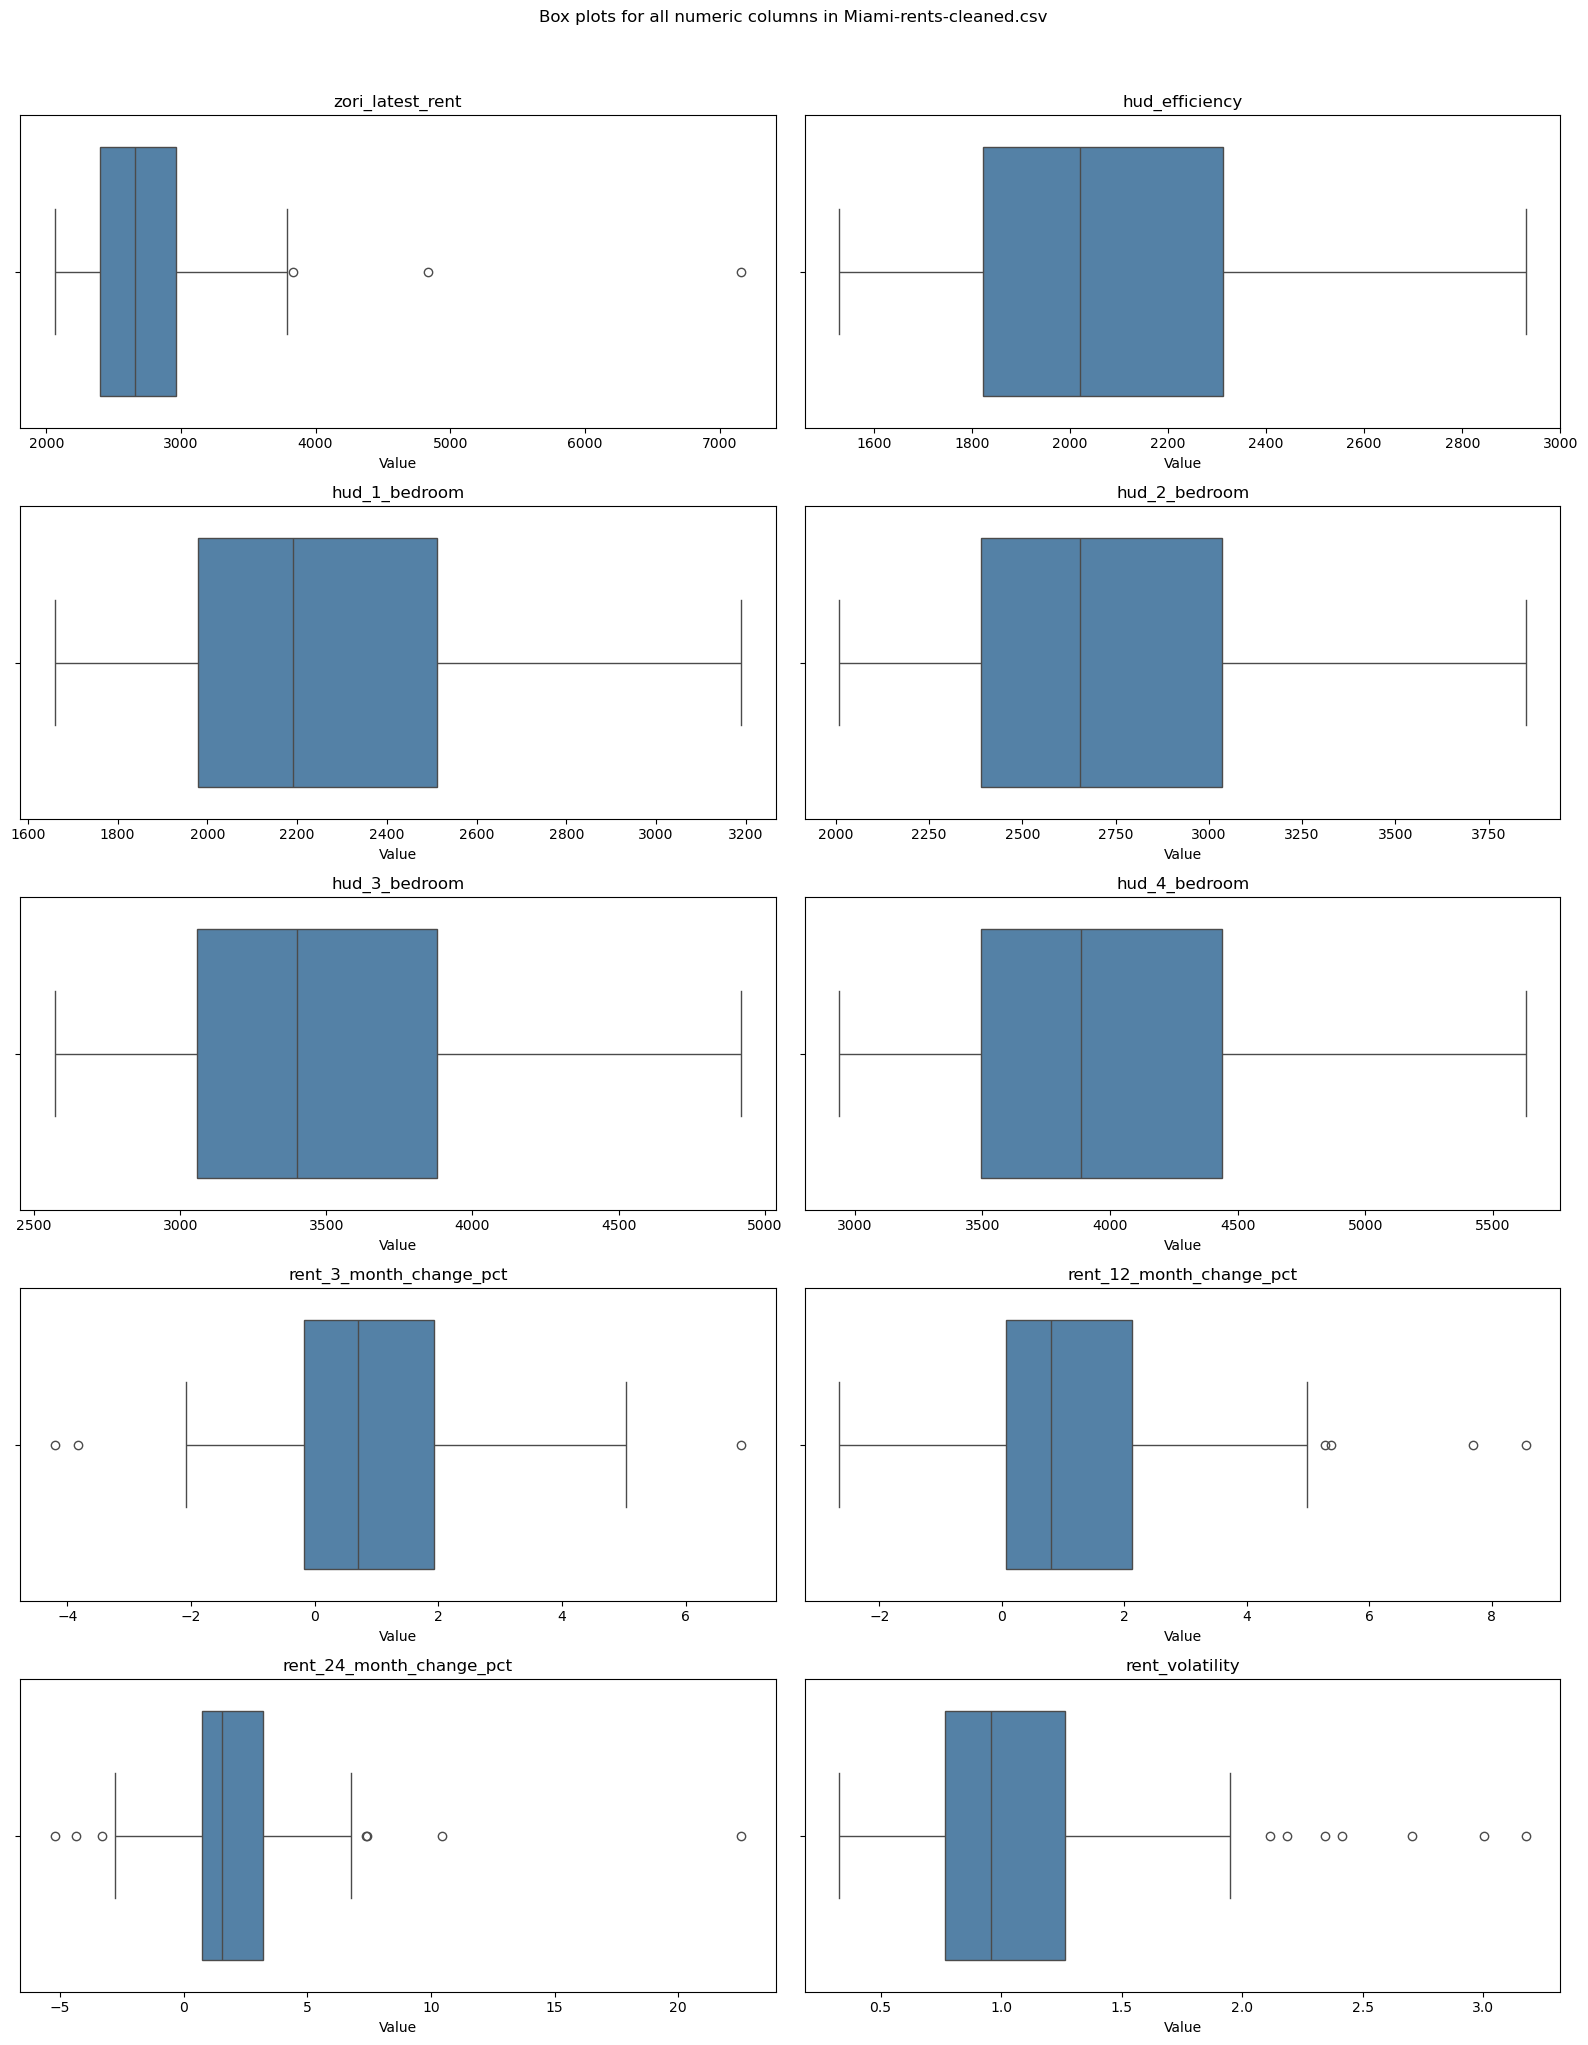

In [72]:
saved_rents = pd.read_csv(CLEANED_RENT_PATH, dtype={"zip_code": "string"})
numeric_columns = saved_rents.select_dtypes(include="number").columns.tolist()
columns_per_row = 2
rows = math.ceil(len(numeric_columns) / columns_per_row)
figure, axes = plt.subplots(rows, columns_per_row, figsize=(16, rows * 4), squeeze=False)

for index, column in enumerate(numeric_columns):
    row, column_index = divmod(index, columns_per_row)
    values = saved_rents[column].dropna()
    sns.boxplot(x=values, ax=axes[row, column_index], color="steelblue")
    axes[row, column_index].set_title(column)
    axes[row, column_index].set_xlabel("Value")

for index in range(len(numeric_columns), rows * columns_per_row):
    row, column_index = divmod(index, columns_per_row)
    axes[row, column_index].set_visible(False)

figure.suptitle("Box plots for all numeric columns in Miami-rents-cleaned.csv", y=1.02)
figure.tight_layout()
plt.show()


## Clean trasnit data 
here we will clean the trasnit data from /Users/joanachoong/Flow-1B-responsible-ai-prototype-for-personalized-neighborhood-recommendations/data/raw/new/miami_transit.csv

1. perform te EDA operation which includes
   1. print the first few column 
   2. find out whihch one ahs missing columns ( o/ N/A)
   3. find the data type for each column ( categorise the numerical value and string value )
   4. use box plot to find out the data disctribution for numerical values 

First five rows:


,zip_code,transit_stop_count,unique_route_count,transit_types,bus_route_count,metrorail_route_count,metromover_route_count,weekday_departures,saturday_departures,sunday_departures,...,weekend_median_headway_minutes,morning_peak_departures,evening_peak_departures,accessible_stop_share,wheelchair_accessible_trip_share,bike_allowed_trip_share,gtfs_agency,service_start_date,service_end_date,data_as_of
0,33010,157,12,bus|metrorail,11,1,0,7038,4347.0,2871.0,...,22.350000,843,1258,0.0,0.741091,0.741091,Miami-Dade Transit,20210101,20271231,2026-10-27
1,33012,149,6,bus,6,0,0,6741,4327.0,3204.0,...,22.050000,769,1146,0.0,0.817755,0.817755,Miami-Dade Transit,20210101,20271231,2026-10-27
2,33013,88,7,bus,7,0,0,3686,1755.0,1325.0,...,93.283333,479,695,0.0,0.603163,0.603163,Miami-Dade Transit,20210101,20271231,2026-10-27
3,33014,66,6,bus,6,0,0,3168,1946.0,1366.0,...,21.800000,304,469,0.0,0.979630,0.979630,Miami-Dade Transit,20210101,20271231,2026-10-27
4,33015,54,6,bus,6,0,0,2657,1658.0,1363.0,...,18.166667,273,421,0.0,1.000000,1.000000,Miami-Dade Transit,20210101,20271231,2026-10-27



Shape: (78, 21)

Column data types:


,dtype
zip_code,string[python]
transit_stop_count,int64
unique_route_count,int64
transit_types,object
bus_route_count,int64
metrorail_route_count,int64
metromover_route_count,int64
weekday_departures,int64
saturday_departures,float64
sunday_departures,float64


Numeric columns: ['transit_stop_count', 'unique_route_count', 'bus_route_count', 'metrorail_route_count', 'metromover_route_count', 'weekday_departures', 'saturday_departures', 'sunday_departures', 'weekday_median_headway_minutes', 'weekend_median_headway_minutes', 'morning_peak_departures', 'evening_peak_departures', 'accessible_stop_share', 'wheelchair_accessible_trip_share', 'bike_allowed_trip_share', 'service_start_date', 'service_end_date']
String columns: ['zip_code', 'transit_types', 'gtfs_agency', 'data_as_of']

Missing and zero values in numeric columns:


,missing_count,missing_percent,zero_count,zero_percent
transit_stop_count,0,0.000000,0,0.000000
unique_route_count,0,0.000000,0,0.000000
bus_route_count,0,0.000000,0,0.000000
metrorail_route_count,0,0.000000,64,82.051282
metromover_route_count,0,0.000000,73,93.589744
weekday_departures,0,0.000000,0,0.000000
saturday_departures,3,3.846154,0,0.000000
sunday_departures,3,3.846154,0,0.000000
weekday_median_headway_minutes,0,0.000000,0,0.000000
weekend_median_headway_minutes,3,3.846154,0,0.000000



Missing values in all columns:


,missing_count
zip_code,0
transit_stop_count,0
unique_route_count,0
transit_types,0
bus_route_count,0
metrorail_route_count,0
metromover_route_count,0
weekday_departures,0
saturday_departures,3
sunday_departures,3


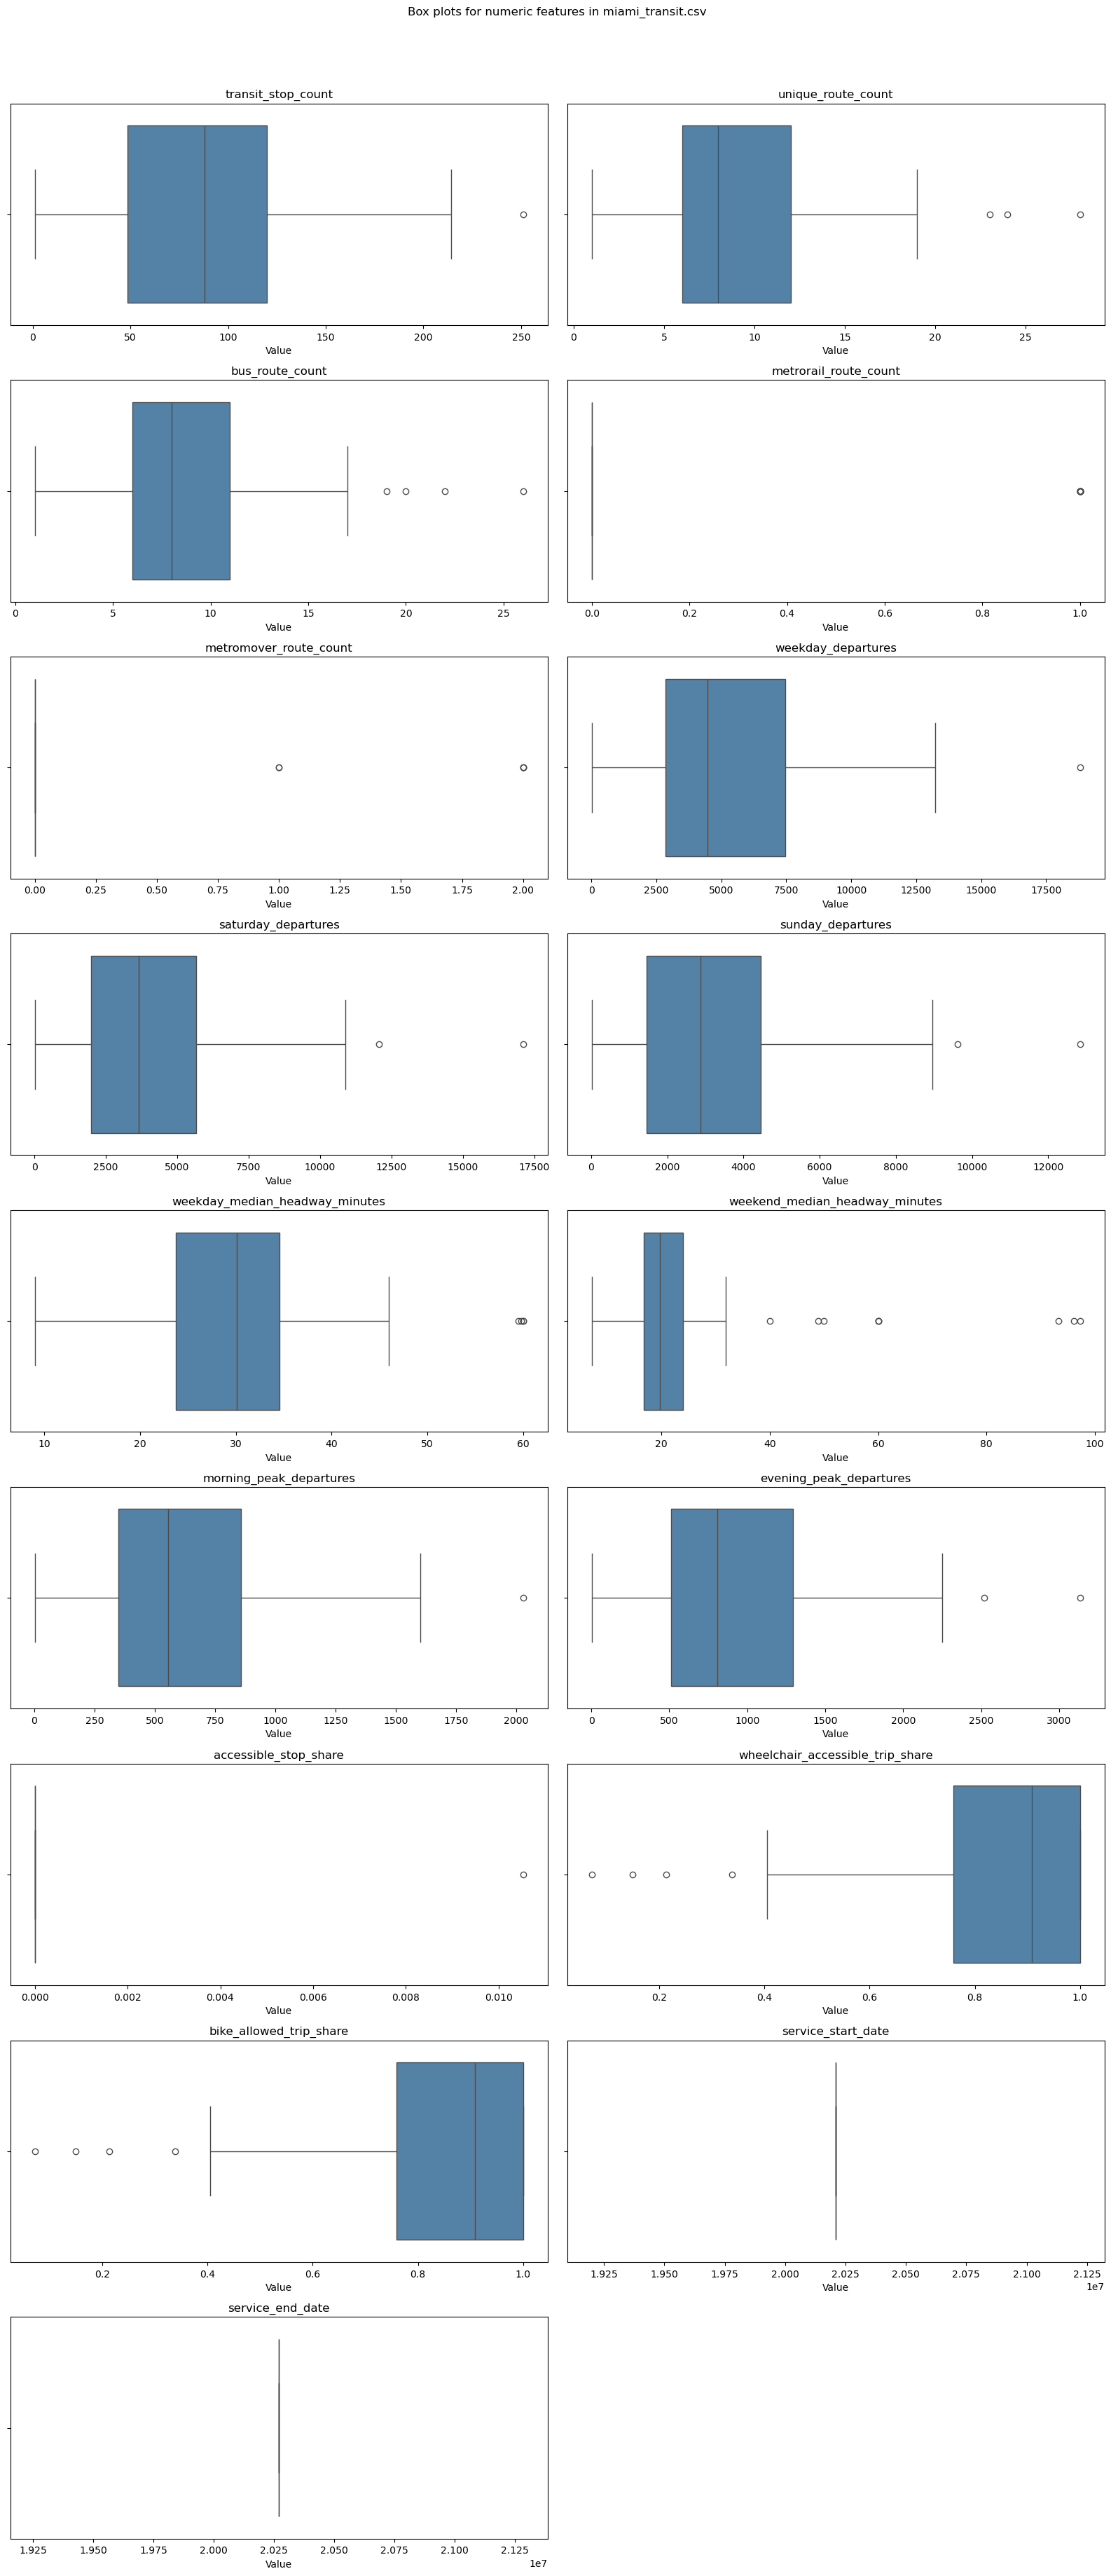

In [73]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TRANSIT_PATH = Path(
    "/Users/joanachoong/Flow-1B-responsible-ai-prototype-for-personalized-neighborhood-recommendations/data/raw/new/miami_transit.csv"
)
miami_transit = pd.read_csv(TRANSIT_PATH, dtype={"zip_code": "string"})

print("First five rows:")
display(miami_transit.head())
print(f"\nShape: {miami_transit.shape}")

print("\nColumn data types:")
display(miami_transit.dtypes.rename("dtype").to_frame())

numeric_columns = miami_transit.select_dtypes(include="number").columns.tolist()
string_columns = miami_transit.select_dtypes(include=["object", "string"]).columns.tolist()
print("Numeric columns:", numeric_columns)
print("String columns:", string_columns)

numeric_quality = pd.DataFrame({
    "missing_count": miami_transit[numeric_columns].isna().sum(),
    "missing_percent": miami_transit[numeric_columns].isna().mean().mul(100),
    "zero_count": miami_transit[numeric_columns].eq(0).sum(),
    "zero_percent": miami_transit[numeric_columns].eq(0).mean().mul(100),
})
print("\nMissing and zero values in numeric columns:")
display(numeric_quality)

print("\nMissing values in all columns:")
display(miami_transit.isna().sum().rename("missing_count").to_frame())

columns_per_row = 2
rows = math.ceil(len(numeric_columns) / columns_per_row)
figure, axes = plt.subplots(rows, columns_per_row, figsize=(16, rows * 4), squeeze=False)
for index, column in enumerate(numeric_columns):
    row, column_index = divmod(index, columns_per_row)
    sns.boxplot(x=miami_transit[column].dropna(), ax=axes[row, column_index], color="steelblue")
    axes[row, column_index].set_title(column)
    axes[row, column_index].set_xlabel("Value")
for index in range(len(numeric_columns), rows * columns_per_row):
    row, column_index = divmod(index, columns_per_row)
    axes[row, column_index].set_visible(False)
figure.suptitle("Box plots for numeric features in miami_transit.csv", y=1.02)
figure.tight_layout()
plt.show()


In [74]:
# drop the folloing columns , service start date and end date acessible stop share ,
miami_transit.drop(columns=['service_end_date','service_start_date','accessible_stop_share','gtfs_agency', 'data_as_of'],inplace=True)

In [75]:
transit_type_dummies = miami_transit["transit_types"].str.get_dummies(sep="|")
transit_type_dummies = transit_type_dummies.add_prefix("transit_type_")

miami_transit = miami_transit.drop(
    columns=["transit_types"]
).join(transit_type_dummies)

display(miami_transit.head())

,zip_code,transit_stop_count,unique_route_count,bus_route_count,metrorail_route_count,metromover_route_count,weekday_departures,saturday_departures,sunday_departures,weekday_median_headway_minutes,weekend_median_headway_minutes,morning_peak_departures,evening_peak_departures,wheelchair_accessible_trip_share,bike_allowed_trip_share,transit_type_bus,transit_type_metromover,transit_type_metrorail
0,33010,157,12,11,1,0,7038,4347.0,2871.0,36.000000,22.350000,843,1258,0.741091,0.741091,1,0,1
1,33012,149,6,6,0,0,6741,4327.0,3204.0,33.258333,22.050000,769,1146,0.817755,0.817755,1,0,0
2,33013,88,7,7,0,0,3686,1755.0,1325.0,40.116667,93.283333,479,695,0.603163,0.603163,1,0,0
3,33014,66,6,6,0,0,3168,1946.0,1366.0,30.275000,21.800000,304,469,0.979630,0.979630,1,0,0
4,33015,54,6,6,0,0,2657,1658.0,1363.0,31.533333,18.166667,273,421,1.000000,1.000000,1,0,0


In [77]:
departure_columns = ["saturday_departures", "sunday_departures"]

miami_transit[departure_columns] = (
    miami_transit[departure_columns]
    .fillna(miami_transit[departure_columns].median())
    .round()
    .astype("int64")
)
miami_transit[["saturday_departures", "sunday_departures"]] = (
    miami_transit[["saturday_departures", "sunday_departures"]]
    .round()
    .astype("Int64")
)

miami_transit.head()

,zip_code,transit_stop_count,unique_route_count,bus_route_count,metrorail_route_count,metromover_route_count,weekday_departures,saturday_departures,sunday_departures,weekday_median_headway_minutes,weekend_median_headway_minutes,morning_peak_departures,evening_peak_departures,wheelchair_accessible_trip_share,bike_allowed_trip_share,transit_type_bus,transit_type_metromover,transit_type_metrorail
0,33010,157,12,11,1,0,7038,4347,2871,36.000000,22.350000,843,1258,0.741091,0.741091,1,0,1
1,33012,149,6,6,0,0,6741,4327,3204,33.258333,22.050000,769,1146,0.817755,0.817755,1,0,0
2,33013,88,7,7,0,0,3686,1755,1325,40.116667,93.283333,479,695,0.603163,0.603163,1,0,0
3,33014,66,6,6,0,0,3168,1946,1366,30.275000,21.800000,304,469,0.979630,0.979630,1,0,0
4,33015,54,6,6,0,0,2657,1658,1363,31.533333,18.166667,273,421,1.000000,1.000000,1,0,0


In [78]:
from pathlib import Path

CLEANED_TRANSIT_PATH = (
    Path.cwd().parent / "data" / "cleaned" / "new" / "miami-transit-cleaned.csv"
)

CLEANED_TRANSIT_PATH.parent.mkdir(parents=True, exist_ok=True)

miami_transit.to_csv(
    CLEANED_TRANSIT_PATH,
    index=False,
    lineterminator="\n",
)

print(f"Saved cleaned transit data to: {CLEANED_TRANSIT_PATH}")
print(f"Shape: {miami_transit.shape}")
display(miami_transit.head())

Saved cleaned transit data to: /Users/joanachoong/Flow-1B-responsible-ai-prototype-for-personalized-neighborhood-recommendations/data/cleaned/new/miami-transit-cleaned.csv
Shape: (78, 18)


,zip_code,transit_stop_count,unique_route_count,bus_route_count,metrorail_route_count,metromover_route_count,weekday_departures,saturday_departures,sunday_departures,weekday_median_headway_minutes,weekend_median_headway_minutes,morning_peak_departures,evening_peak_departures,wheelchair_accessible_trip_share,bike_allowed_trip_share,transit_type_bus,transit_type_metromover,transit_type_metrorail
0,33010,157,12,11,1,0,7038,4347,2871,36.000000,22.350000,843,1258,0.741091,0.741091,1,0,1
1,33012,149,6,6,0,0,6741,4327,3204,33.258333,22.050000,769,1146,0.817755,0.817755,1,0,0
2,33013,88,7,7,0,0,3686,1755,1325,40.116667,93.283333,479,695,0.603163,0.603163,1,0,0
3,33014,66,6,6,0,0,3168,1946,1366,30.275000,21.800000,304,469,0.979630,0.979630,1,0,0
4,33015,54,6,6,0,0,2657,1658,1363,31.533333,18.166667,273,421,1.000000,1.000000,1,0,0
